# 2 — Main Network Criticality Analysis, Costa Rica (Single Point of Failure)

## Purpose
Quantify the criticality of every section of the Costa Rican main road network through asingle-point-of-failure (SPOF) percolation analysis. Each physical road is removed in turn(together with its reverse edge) and the population-weighted origin–destination travel timesare recomputed. The resulting disruption is expressed as vehicle / passenger / tonnage hoursand kilometres lost.

## Inputs
| File | Description |
|------|-------------|
| `intermediate_results/gpkg/network/main_network_directed.gpkg`| Directed, AADT-attributed road network produced in 1b (EPSG:8908) |
| `input_files/CENTROS_POBLACION/centros_poblados_localidades.shp` | Locality points with INEC projected population (`INEC_PROY`, EPSG:8908)|

## Outputs
| File | Description |
|------|-------------|
| `intermediate_results/gpkg/travel_disruptions/criticality_results.gpkg` | Per-edge SPOF criticality metrics |
| `figures/SPOF_results_2x2.png` | Average delay, VHL, average detour, VKL |
| `figures/SPOF_PHL_THL_PKL_TKL.png` | Passenger / tonnage hours and kilometres lost |
| `figures/SPOF_PHL_TKL_snapped_localities.png` | PHL and TKL map with snapped localities coloured by distance to the network |
| `figures/SPOF_by_road_type_boxplot.png` | Disruption by road class (box) |
| `figures/SPOF_by_road_type_violin.png` | Disruption by road class (violin) |
| `figures/SPOF_AADT_vs_criticality.png` | AADT vs criticality with regression |

## Key processing steps
1. **Load network** — read the directed GeoPackage and build a directed igraph graph on   `from_id` / `to_id`, carrying only routing attributes.
2. **Origin–destination nodes** — load locality points, snap each to the nearest network node,   aggregate `INEC_PROY` per node.
3. **Baseline matrices** — all-pairs shortest paths weighted by `fft`(road_length / speed) (hours) and `road_length` (km).
4. **Travel demand** — gravity model: demand ∝ Pop_o × Pop_d × exp(−decay × normalised distance).
5. **SPOF percolation** — remove each `physical_edge_id` group, recompute the OD time matrix,   summarise isolated / unaffected / delayed trips and demand-weighted disruption.
6. **Criticality metrics** — VHL / VKL from `total_aadt`, plus PHL / THL / PKL / TKL from the   seven Costa Rican traffic categories.
7. **Save & visualise**.## Assumptions recorded in this notebook- Everything stays in **EPSG:8908** (CR-SIRGAS / CRTM05, metres); Web Mercator is used only for basemaps.- A share of AADT is imputed in 1b — see the `aadt_imputed` flag.- The isolation penalty is **derived from the observed maximum baseline travel time**, not hard-coded.- Passenger and freight factors are defined once in `PASSENGER_FACTORS` / `FREIGHT_FACTORS`;  `pickup_trucks` is counted on both sides, and there is no articulated-vehicle class in the CR data.

## 1. Imports and configuration

In [1]:
# Standard library
import warnings
from pathlib import Path

# Third-party - data and scientific computing
import contextily as cx
import geopandas as gpd
import igraph as ig
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from tqdm import tqdm

# Shapely
import shapely
from shapely import STRtree

# Matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=RuntimeWarning)

In [2]:
# ---- Paths -------------------------------------------------------------
BASE_DIR = Path.cwd().parent          # notebook lives in /notebooks
data_path = BASE_DIR / "input_files"
figure_path = BASE_DIR / "figures"
intermediate_path = BASE_DIR / "intermediate_results"

network_gpkg = intermediate_path / "gpkg" / "network" / "main_network_directed.gpkg"
population_shp = data_path / "CENTROS_POBLACION" / "centros_poblados_localidades.shp"

criticality_results_path = (
    intermediate_path / "gpkg" / "travel_disruptions" / "criticality_results.gpkg"
)

physical_results_path = (
    intermediate_path / "gpkg" / "travel_disruptions" / "physical_criticality_results.gpkg"
)
figure_path.mkdir(parents=True, exist_ok=True)
criticality_results_path.parent.mkdir(parents=True, exist_ok=True)

# ---- Constants ---------------------------------------------------------
WORKING_EPSG = 8908          # CR-SIRGAS / CRTM05, metres
DIST_DECAY = 1.0             # gravity model decay
MAX_TRIPS = 25_000           # scaling of the busiest OD pair
ISOLATION_PENALTY_FACTOR = 2.0   # multiple of max baseline OD time (see section 6)
FAR_SNAP_WARN_M = 5_000      # localities snapping further than this are reported

# Routing attributes carried onto graph edges. Deliberately minimal: the
# percolation loop copies the graph once per iteration, so attaching geometry
# or the full attribute table would be very expensive.
GRAPH_EDGE_ATTRS = ["id", "physical_edge_id", "road_length", "fft"]

for p in (network_gpkg, population_shp):
    if not p.exists():
        raise FileNotFoundError(
            f"Missing input: {p}\n"
            "If this path lives on OneDrive, make sure the folder is downloaded locally "
            "('Always keep on this device') — cloud placeholders cannot be opened."
        )

print(f"Base directory : {BASE_DIR}")
print(f"Network        : {network_gpkg}")
print(f"Population     : {population_shp}")

Base directory : /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR
Network        : /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/gpkg/network/main_network_directed.gpkg
Population     : /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/input_files/CENTROS_POBLACION/centros_poblados_localidades.shp


## 2. Load and validate the directed network
The network comes from 1b and is already directed, AADT-attributed, speed-attributed andstrongly connected. This section re-validates that contract before anything depends on it.

In [3]:
edges = gpd.read_file(network_gpkg, layer="main_network_directed")

print(f"Directed edges : {len(edges):,}")
print(f"CRS            : {edges.crs}")
print(f"Geometry types : {sorted(edges.geom_type.unique())}")

# --- contract checks ----------------------------------------------------
required = [
    "from_id", "to_id", "id", "physical_edge_id", "direction_side",
    "road_length", "fft", "speed", "total_aadt", "CLASE",
    "motorcycles", "pickup_trucks", "passenger_cars", "buses",
    "light_trucks", "medium_trucks", "heavy_trucks",
]
missing = [c for c in required if c not in edges.columns]
assert not missing, f"Missing required columns: {missing}"

assert edges.crs is not None and edges.crs.to_epsg() == WORKING_EPSG, (
    f"Expected EPSG:{WORKING_EPSG}, found {edges.crs}"
)
assert edges.crs.axis_info[0].unit_name == "metre", "Working CRS must be metric"

for col in ["from_id", "to_id", "id", "physical_edge_id", "road_length", "fft"]:
    assert edges[col].notna().all(), f"{col} contains nulls"

assert (edges["road_length"] > 0).all(), "road_length must be strictly positive"
assert np.isfinite(edges["fft"]).all() and (edges["fft"] > 0).all(), "fft must be finite and positive"
assert edges["id"].is_unique, "edge id must be unique"

# CLASE carries nulls in the source; label them so groupby/plots keep them visible.
edges["CLASE"] = edges["CLASE"].fillna("Sin clasificar")

print("\nRoad classes:")
print(edges["CLASE"].value_counts().to_string())
print(f"\nTotal directed length : {edges['road_length'].sum():,.0f} km")
print(f"Unique physical roads : {edges['physical_edge_id'].nunique():,}")
print(f"AADT imputed edges    : {int(edges['aadt_imputed'].sum()):,} "
      f"({edges['aadt_imputed'].mean() * 100:.1f}%)")

Directed edges : 9,764
CRS            : EPSG:8908
Geometry types : ['LineString']

Road classes:
CLASE
Local             4223
Secundaria        2451
Terciaria         1451
Primaria          1393
Sin clasificar     246

Total directed length : 29,528 km
Unique physical roads : 5,012
AADT imputed edges    : 3,743 (38.3%)


In [4]:
# --- build the directed graph ------------------------------------------
# igraph's TupleList takes the FIRST TWO columns as the edge endpoints, so the
# column order here is load-bearing. Selecting explicitly (rather than relying
# on the incoming column order) is what keeps the graph meaningful.
graph_cols = ["from_id", "to_id"] + GRAPH_EDGE_ATTRS
assert graph_cols[0] == "from_id" and graph_cols[1] == "to_id"

graph_frame = edges[graph_cols]
graph = ig.Graph.TupleList(
    graph_frame.itertuples(index=False),
    edge_attrs=GRAPH_EDGE_ATTRS,
    directed=True,
)

print(f"Graph vertices : {graph.vcount():,}")
print(f"Graph edges    : {graph.ecount():,}")
assert graph.ecount() == len(edges), "Edge count mismatch — check column ordering"

# 1b guarantees a strongly connected giant component; a failure here means the
# network input is stale rather than that the analysis is wrong.
n_strong = len(graph.connected_components(mode="strong"))
print(f"Strong components : {n_strong}")
assert n_strong == 1, (
    f"Graph is not strongly connected ({n_strong} components) — "
    "re-run 1b to regenerate main_network_directed.gpkg"
)

Graph vertices : 3,909
Graph edges    : 9,764
Strong components : 1


In [5]:
# --- sister-edge pairing on physical_edge_id ---------------------------
# Pairing by reversed (source, target) mis-handles parallel edges. The 1b
# contract is exactly one directed edge per Unidireccional road and exactly
# two per Bidireccional road, so physical_edge_id is the reliable key.
edge_index_by_id = {eid: i for i, eid in enumerate(graph.es["id"])}
physical_groups = (
    pd.Series(graph.es["id"], name="id")
    .groupby(pd.Series(graph.es["physical_edge_id"], name="physical_edge_id"))
    .apply(list)
)

group_sizes = physical_groups.map(len).value_counts().sort_index()
print("Directed edges per physical road:")
print(group_sizes.to_string())
assert set(group_sizes.index) <= {1, 2}, "physical_edge_id groups must contain 1 or 2 edges"

print(f"\nPhysical roads to test : {len(physical_groups):,}")

Directed edges per physical road:
id
1     260
2    4752

Physical roads to test : 5,012


## 3. Load and audit the locality population layer
`INEC_PROY` is the INEC projected population per locality. The layer is already in EPSG:8908,so no reprojection is required — but the CRS is asserted rather than assumed, and `set_crs`is never used (it would silently relabel and displace the points).

In [6]:
localities = gpd.read_file(population_shp)

print(f"Localities     : {len(localities):,}")
print(f"CRS            : {localities.crs}")
print(f"Geometry types : {sorted(localities.geom_type.unique())}")
print(f"\nColumns: {list(localities.columns)}")
print("\nNull counts:")
print(localities.isna().sum().to_string())
print("\nSample:")
print(localities[["NOMBRE", "PROVINCIA", "CANTÓN", "TIPO", "INEC_PROY"]].head().to_string(index=False))

Localities     : 493
CRS            : EPSG:8908
Geometry types : ['Point']

Columns: ['gml_id', 'OBJECTID', 'CÓDIGO', 'TIPO', 'NOMBRE', 'NOMBRE_NO_', 'FUENTE', 'CÓDIGO_DTA', 'CÓDIGO_DE_', 'CÓDIGO_D_1', 'PROVINCIA', 'CANTÓN', 'DISTRITO', 'INEC_PROY', 'geometry']

Null counts:
gml_id        0
OBJECTID      0
CÓDIGO        0
TIPO          0
NOMBRE        0
NOMBRE_NO_    0
FUENTE        0
CÓDIGO_DTA    0
CÓDIGO_DE_    0
CÓDIGO_D_1    0
PROVINCIA     0
CANTÓN        0
DISTRITO      0
INEC_PROY     0
geometry      0

Sample:
        NOMBRE  PROVINCIA         CANTÓN                         TIPO  INEC_PROY
     La Cuesta Puntarenas     Corredores Poblado/Cabecera de Distrito       5531
        Laurel Puntarenas     Corredores Poblado/Cabecera de Distrito      12566
        Canoas Puntarenas     Corredores Poblado/Cabecera de Distrito      16230
Puerto Jiménez Puntarenas Puerto Jiménez    Ciudad/Cabecera de Cantón      13765
         Neily Puntarenas     Corredores    Ciudad/Cabecera de Cantón 

In [7]:
POP_COL = "INEC_PROY"
NAME_COL = "NOMBRE"

assert localities.crs is not None and localities.crs.to_epsg() == WORKING_EPSG, (
    f"Expected EPSG:{WORKING_EPSG}, found {localities.crs}"
)

# Reproject only if needed. Never set_crs — the layer is already projected.
if localities.crs.to_epsg() != edges.crs.to_epsg():
    localities = localities.to_crs(edges.crs)

# Points already; take centroids only if the layer is polygonal.
if localities.geom_type.isin(["Polygon", "MultiPolygon"]).any():
    print("Polygonal geometry detected — using centroids")
    localities = localities.copy()
    localities["geometry"] = localities.geometry.centroid

n_before = len(localities)
localities[POP_COL] = pd.to_numeric(localities[POP_COL], errors="coerce")
OD_nodes = localities.loc[
    localities[POP_COL].notna() & (localities[POP_COL] > 0) & localities.geometry.notna()
].copy()
dropped = n_before - len(OD_nodes)

OD_nodes = OD_nodes.rename(columns={POP_COL: "population"}).reset_index(drop=True)

# A readable label. NOMBRE repeats across cantons, so qualify it.
OD_nodes["label"] = OD_nodes[NAME_COL].astype(str) + " (" + OD_nodes["CANTÓN"].astype(str) + ")"

print(f"Localities retained : {len(OD_nodes):,} (dropped {dropped} null/non-positive)")
print(f"Total population    : {OD_nodes['population'].sum():,.0f}")
print(f"Population range    : {OD_nodes['population'].min():,.0f} – {OD_nodes['population'].max():,.0f}")
print("\nLargest localities:")
print(OD_nodes.nlargest(8, "population")[["label", "PROVINCIA", "population"]].to_string(index=False))

Localities retained : 493 (dropped 0 null/non-positive)
Total population    : 5,167,278
Population range    : 414 – 90,730

Largest localities:
                                   label  PROVINCIA  population
                        Pavas (San José)   San José       90730
                       Liberia (Liberia) Guanacaste       68040
               Hatillo Centro (San José)   San José       60681
                 San Francisco (Heredia)    Heredia       60480
                     San José (Alajuela)   Alajuela       54105
                           Limón (Limón)      Limón       53629
San Isidro de El General (Pérez Zeledón)   San José       46556
                     Alajuela (Alajuela)   Alajuela       46314


## 4. Snap localities to network nodes
Both layers are metric and in the same CRS, so snap distances below are directly interpretablein metres.

In [8]:
# Network node geometry, keyed by the node ids used in the graph.
vertex_lookup = {name: idx for idx, name in enumerate(graph.vs["name"])}

start_points = shapely.get_point(edges.geometry.values, 0)
end_points = shapely.get_point(edges.geometry.values, -1)

node_geom = {}
node_geom.update(dict(zip(edges["from_id"].to_numpy(), start_points)))
node_geom.update(dict(zip(edges["to_id"].to_numpy(), end_points)))

nodes = gpd.GeoDataFrame(
    {"node_id": list(node_geom.keys())},
    geometry=list(node_geom.values()),
    crs=edges.crs,
)
missing_nodes = [n for n in nodes["node_id"] if n not in vertex_lookup]
assert not missing_nodes, f"{len(missing_nodes)} node ids absent from the graph"
nodes["vertex_id"] = nodes["node_id"].map(vertex_lookup)

print(f"Network nodes : {len(nodes):,}")

# Nearest network node per locality.
nodes_sindex = STRtree(nodes.geometry.values)
nearest_idx = nodes_sindex.nearest(OD_nodes.geometry.values)
OD_nodes["vertex_id"] = nodes["vertex_id"].to_numpy()[nearest_idx]
OD_nodes["snap_distance_m"] = shapely.distance(
    OD_nodes.geometry.values, nodes.geometry.to_numpy()[nearest_idx]
)

Network nodes : 3,909


Snap distance (metres):
  min / median / mean / max : 8 / 247 / 618 / 16,873
  p75 : 687
  p90 : 1,425
  p95 : 2,144
  p99 : 5,380

Localities snapping further than 5,000 m : 6 (1.2%)
                          label  PROVINCIA  population  snap_distance_m
Puerto Jiménez (Puerto Jiménez) Puntarenas       13765     16872.644962
    Barra del Colorado (Pococí)      Limón        5025     12342.366247
           Nancite (Puntarenas) Puntarenas        1675      8158.460803
              Cabanga (Guatuso)   Alajuela        1109      7304.365178
             Amubri (Talamanca)      Limón        8853      5845.082926
               Delicias (Upala)   Alajuela        5413      5340.043189


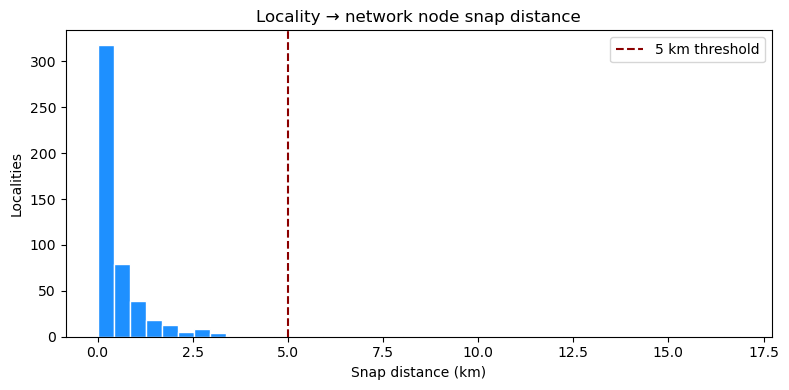

In [9]:
snap = OD_nodes["snap_distance_m"]
print("Snap distance (metres):")
print(f"  min / median / mean / max : {snap.min():,.0f} / {snap.median():,.0f} / "
      f"{snap.mean():,.0f} / {snap.max():,.0f}")
for q in (0.75, 0.90, 0.95, 0.99):
    print(f"  p{int(q * 100)} : {snap.quantile(q):,.0f}")

far = OD_nodes.loc[snap > FAR_SNAP_WARN_M]
print(f"\nLocalities snapping further than {FAR_SNAP_WARN_M:,} m : {len(far)} "
      f"({len(far) / len(OD_nodes) * 100:.1f}%)")
if len(far):
    print(far.nlargest(10, "snap_distance_m")[
        ["label", "PROVINCIA", "population", "snap_distance_m"]
    ].to_string(index=False))

# Policy: far-snapping localities are RETAINED and flagged, not dropped. They are
# real population that depends on the network; dropping them would understate
# disruption in exactly the remote areas where isolation matters most. The flag is
# kept so the assumption stays visible downstream.
OD_nodes["snap_far"] = snap > FAR_SNAP_WARN_M

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(snap / 1000, bins=40, color="#1E90FF", edgecolor="white")
ax.axvline(FAR_SNAP_WARN_M / 1000, color="#8B0000", linestyle="--",
           label=f"{FAR_SNAP_WARN_M / 1000:.0f} km threshold")
ax.set_xlabel("Snap distance (km)")
ax.set_ylabel("Localities")
ax.set_title("Locality → network node snap distance")
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
# Aggregate population onto shared network nodes.
grouped_OD = (
    OD_nodes.groupby("vertex_id")
    .agg(
        geometry=("geometry", "first"),
        population=("population", "sum"),
        label=("label", "first"),
        n_localities=("label", "size"),
    )
    .reset_index()
)
grouped_OD = gpd.GeoDataFrame(grouped_OD, geometry="geometry", crs=edges.crs)

collapsed = len(OD_nodes) - len(grouped_OD)
print(f"OD nodes after aggregation : {len(grouped_OD):,} "
      f"({collapsed} localities collapsed onto shared nodes)")
assert grouped_OD["population"].sum() == OD_nodes["population"].sum(), "population lost in aggregation"
print(f"Population preserved       : {grouped_OD['population'].sum():,.0f}")
print(f"OD matrix size             : {len(grouped_OD)} x {len(grouped_OD)}")

OD nodes after aggregation : 485 (8 localities collapsed onto shared nodes)
Population preserved       : 5,167,278
OD matrix size             : 485 x 485


## 5. Baseline travel matrices and gravity demand

In [11]:
def run_shortest_paths(graph, OD_nodes, weighting="fft"):
    """All-pairs shortest path matrix between OD vertices under the given edge weight."""
    vertex_ids = OD_nodes.vertex_id.values
    return np.matrix(graph.distances(source=vertex_ids, target=vertex_ids, weights=weighting))


def create_demand(node_pop, OD_orig, dist_decay=DIST_DECAY, maxtrips=MAX_TRIPS):
    """Gravity model: Demand_a,b = Pop_a * Pop_b * exp(-decay * normalised distance).

    Vectorised equivalent of the original double loop. Note that demand enters the
    analysis only as weights in a weighted average, so its absolute scale cancels out
    of the reported disruption; `maxtrips` matters only through the np.ceil rounding
    below, which would flatten the weights if it were set very low.
    """
    normalized_dist = np.asarray(OD_orig / OD_orig.max())
    pop = np.asarray(node_pop, dtype=float)
    demand = np.outer(pop, pop) * np.exp(-dist_decay * normalized_dist)
    np.fill_diagonal(demand, 0)
    demand = (demand / demand.max()) * maxtrips
    return np.ceil(demand).astype(int)

In [12]:
# Baseline matrices. OD_base_time keeps a zero diagonal and drives the demand model;
# the NaN-diagonal copies are used for the disruption comparison.
OD_base_time = run_shortest_paths(graph, grouped_OD, weighting="fft")
assert np.isfinite(OD_base_time).all(), "Non-finite baseline travel time — graph not strongly connected?"

demand = create_demand(grouped_OD.population.values, OD_base_time)

OD_orig_time = OD_base_time.copy()
OD_orig_dist = run_shortest_paths(graph, grouped_OD, weighting="road_length")
assert np.isfinite(OD_orig_dist).all(), "Non-finite baseline distance"

np.fill_diagonal(OD_orig_time, np.nan)
np.fill_diagonal(OD_orig_dist, np.nan)

# Implied speed per OD pair (km/h), used to convert delay into detour distance.
speed_ratio = np.array(OD_orig_dist) / np.array(OD_orig_time)

max_baseline_hours = float(np.nanmax(OD_orig_time))
ISOLATION_PENALTY_HOURS = float(np.ceil(max_baseline_hours * ISOLATION_PENALTY_FACTOR))

print(f"Baseline travel time  : max {max_baseline_hours:.2f} h, "
      f"mean {np.nanmean(OD_orig_time):.2f} h")
print(f"Baseline distance     : max {np.nanmax(OD_orig_dist):,.0f} km, "
      f"mean {np.nanmean(OD_orig_dist):,.0f} km")
print(f"Implied speed         : mean {np.nanmean(speed_ratio):.1f} km/h")
print(f"\nIsolation penalty     : {ISOLATION_PENALTY_HOURS:.0f} h "
      f"({ISOLATION_PENALTY_FACTOR:g} x the {max_baseline_hours:.2f} h maximum baseline trip)")
print("  Derived from the data so that being cut off is always costlier than the "
      "longest legitimate journey.")
print(f"\nDemand: max {demand.max():,} trips/day on the busiest pair, "
      f"{demand.sum():,} total")

Baseline travel time  : max 10.38 h, mean 2.82 h
Baseline distance     : max 552 km, mean 142 km
Implied speed         : mean 49.8 km/h

Isolation penalty     : 21 h (2 x the 10.38 h maximum baseline trip)
  Derived from the data so that being cut off is always costlier than the longest legitimate journey.

Demand: max 25,000 trips/day on the busiest pair, 99,439,323 total


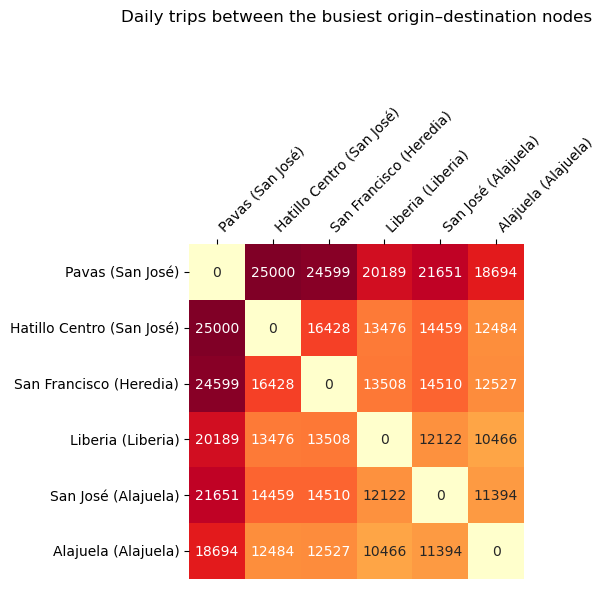

In [13]:
# Demand heatmap for the busiest OD nodes.
row_sums = np.asarray(demand).sum(axis=1)
top_idx = np.argsort(row_sums)[::-1][:6]
sub = np.asarray(demand)[np.ix_(top_idx, top_idx)]
labels = grouped_OD.loc[top_idx, "label"].tolist()

plt.figure(figsize=(8, 6))
sns.heatmap(sub, annot=True, fmt=".0f", cmap="YlOrRd",
            xticklabels=labels, yticklabels=labels, square=True, cbar=False)
plt.xlabel("")
plt.ylabel("")
plt.gca().xaxis.tick_top()
plt.xticks(rotation=45, ha="left")
plt.yticks(rotation=0)
plt.title("Daily trips between the busiest origin–destination nodes", pad=60)
plt.tight_layout()
plt.show()

## 6. Single-point-of-failure percolation
Each physical road is removed together with its reverse edge, and the OD travel-time matrix isrecomputed. Trips left without any route receive `ISOLATION_PENALTY_HOURS`, derived above.
Note on `SummariseOD`: for isolated OD pairs the distance disruption is set to the removedroad's own length. That is a placeholder, not a measured detour — no route exists, so nodetour distance can be computed.

In [14]:
def SummariseOD(OD_time, fail_value, demand, baseline_time, speed_ratio, edge_length,
                frac_counter, distance_disruption, time_disruption):
    """Disruption metrics including demand-weighted average time and distance disruption."""
    adj_time = OD_time - baseline_time

    total_trips = (baseline_time.shape[0] * baseline_time.shape[1]) - baseline_time.shape[0]

    isolated_trips_sum = OD_time[OD_time == fail_value].shape[1]
    pct_isolated = (isolated_trips_sum / total_trips) * 100

    time_unaffected_trips = OD_time[OD_time == baseline_time]
    unaffected_trips = np.array(time_unaffected_trips).shape[1]
    pct_unaffected = (unaffected_trips / total_trips) * 100

    delayed_mask = (np.array(OD_time) != np.array(baseline_time)) & (~np.isnan(np.array(OD_time)))

    delayed_times = np.array(adj_time)[delayed_mask]
    delayed_speeds = np.array(speed_ratio)[delayed_mask]
    delayed_demands = np.array(demand)[delayed_mask]

    isolated_within_delayed = np.array(OD_time)[delayed_mask] == fail_value

    # Rerouted trips: delay x implied speed. Isolated trips: placeholder (see markdown).
    delayed_dists = delayed_times * delayed_speeds
    delayed_dists[isolated_within_delayed] = edge_length

    delayed_trips = delayed_times.shape[0]
    pct_delayed = (delayed_trips / total_trips) * 100

    if len(delayed_times) > 0 and delayed_demands.sum() > 0:
        average_time_disruption = np.average(delayed_times, weights=delayed_demands)
        average_dist_disruption = np.average(delayed_dists, weights=delayed_demands)
    else:
        # No OD pair was delayed at all: the road carries no shortest path between
        # any pair of population centres, so its failure costs zero measured time
        # and distance. This is a real result (a fully redundant road), not missing
        # data, so it is recorded as 0 rather than NaN — NaN would silently drop
        # these roads out of the maps, class breaks and summary statistics.
        average_time_disruption = 0.0
        average_dist_disruption = 0.0

    return (frac_counter, pct_isolated, pct_unaffected, pct_delayed,
            average_time_disruption, average_dist_disruption,
            distance_disruption, time_disruption)

In [15]:
tot_edge_length = float(np.sum(graph.es["road_length"]))
tot_edge_time = float(np.sum(graph.es["fft"]))

# One timed iteration first, so the full run has a realistic ETA.
import time

_probe_ids = physical_groups.iloc[0]
_probe_idx = [edge_index_by_id[i] for i in _probe_ids]
_t0 = time.perf_counter()
_g = graph.copy()
_g.delete_edges(_probe_idx)
_ = run_shortest_paths(_g, grouped_OD, weighting="fft")
_per_iter = time.perf_counter() - _t0

print(f"Single iteration : {_per_iter:.3f} s")
print(f"Physical roads   : {len(physical_groups):,}")
print(f"Estimated total  : {_per_iter * len(physical_groups) / 60:.1f} min")

Single iteration : 0.203 s
Physical roads   : 5,012
Estimated total  : 16.9 min


In [16]:
result_df = []

for physical_id, edge_ids in tqdm(physical_groups.items(), total=len(physical_groups),
                                  desc="percolation"):
    edge_idx = [edge_index_by_id[i] for i in edge_ids]

    # Combined length of the physical road (both directions when bidirectional).
    edge_length = float(sum(graph.es[i]["road_length"] for i in edge_idx))

    exp_g = graph.copy()
    exp_g.delete_edges(edge_idx)

    cur_dis_length = 1 - (np.sum(exp_g.es["road_length"]) / tot_edge_length)
    cur_dis_time = 1 - (np.sum(exp_g.es["fft"]) / tot_edge_time)

    perc_matrix_time = run_shortest_paths(exp_g, grouped_OD, weighting="fft")
    np.fill_diagonal(perc_matrix_time, np.nan)
    perc_matrix_time[np.isinf(perc_matrix_time)] = ISOLATION_PENALTY_HOURS

    results = SummariseOD(
        perc_matrix_time, ISOLATION_PENALTY_HOURS, demand,
        OD_orig_time, speed_ratio, edge_length,
        physical_id, cur_dis_length, cur_dis_time,
    )
    result_df.append(results)

result_df = pd.DataFrame(result_df, columns=[
    "physical_edge_id", "pct_isolated", "pct_unaffected", "pct_delayed",
    "average_time_disruption", "average_dist_disruption",
    "distance_disruption", "time_disruption",
])

n_redundant = (result_df["pct_delayed"] == 0).sum()
print(f"\nPhysical roads tested   : {len(result_df):,}")
print(f"Roads causing isolation : {(result_df['pct_isolated'] > 0).sum():,}")
print(f"Fully redundant roads   : {n_redundant:,} "
      f"({n_redundant / len(result_df) * 100:.1f}%) — removal delays no OD pair, "
      "recorded as zero disruption")
print(result_df[["pct_isolated", "pct_unaffected", "pct_delayed",
                 "average_time_disruption", "average_dist_disruption"]].describe().to_string())

percolation: 100%|██████████| 5012/5012 [21:11<00:00,  3.94it/s]


Physical roads tested   : 5,012
Roads causing isolation : 130
Fully redundant roads   : 1,989 (39.7%) — removal delays no OD pair, recorded as zero disruption
       pct_isolated  pct_unaffected  pct_delayed  average_time_disruption  average_dist_disruption
count   5012.000000     5012.000000  5012.000000              5012.000000              5012.000000
mean       0.017167       98.833662     1.166338                 0.506878                 4.062270
std        0.167274        3.174878     3.174878                 2.689815                10.768411
min        0.000000       71.611996     0.000000                 0.000000                 0.000000
25%        0.000000       99.315839     0.000000                 0.000000                 0.000000
50%        0.000000       99.931839     0.068161                 0.009431                 0.430022
75%        0.000000      100.000000     0.684161                 0.063950                 2.845143
max        4.835989      100.000000    28.388004

## 7. Criticality metrics
Disruption is measured per **physical road**, then joined back onto the directed edges on`physical_edge_id`, so both directions of a bidirectional road carry the same disruption.### Passenger and freight factorsThe Serbian formulation used an `articulated_vehicles` class that does not exist in the CostaRican data. The factors below are stated as explicit assumptions:- `pickup_trucks` is the second-largest CR category and serves both personal and goods  transport, so it is counted on **both** sides at reduced weight. Assigning it wholly to  passengers is the defensible alternative.- There is no articulated class, so the heaviest freight factor is 8.0 t. Costa Rican tonnage  results are therefore **not** comparable with the Serbian ones.

In [17]:
# Passengers per vehicle, by category.
PASSENGER_FACTORS = {
    "motorcycles": 1.2,
    "passenger_cars": 2.0,
    "pickup_trucks": 2.0,
    "buses": 30.0,
}

# Tonnes of freight per vehicle, by category. No articulated class exists in the CR data.
FREIGHT_FACTORS = {
    "pickup_trucks": 0.3,
    "light_trucks": 1.2,
    "medium_trucks": 3.8,
    "heavy_trucks": 8.0,
}

print("Passenger factors (persons/vehicle):")
for k, v in PASSENGER_FACTORS.items():
    print(f"  {k:16} x {v}")
print("Freight factors (tonnes/vehicle):")
for k, v in FREIGHT_FACTORS.items():
    print(f"  {k:16} x {v}")

Passenger factors (persons/vehicle):
  motorcycles      x 1.2
  passenger_cars   x 2.0
  pickup_trucks    x 2.0
  buses            x 30.0
Freight factors (tonnes/vehicle):
  pickup_trucks    x 0.3
  light_trucks     x 1.2
  medium_trucks    x 3.8
  heavy_trucks     x 8.0


In [18]:
gdf_results = edges.merge(result_df, on="physical_edge_id", how="left", validate="many_to_one")

assert len(gdf_results) == len(edges), "merge changed the row count"
assert gdf_results["average_time_disruption"].notna().all(), "unmatched edges after merge"

# Vehicle hours / kilometres lost.
gdf_results["vhl"] = gdf_results["average_time_disruption"] * gdf_results["total_aadt"]
gdf_results["vkl"] = gdf_results["average_dist_disruption"] * gdf_results["total_aadt"]

passengers = sum(gdf_results[col] * f for col, f in PASSENGER_FACTORS.items())
tonnes = sum(gdf_results[col] * f for col, f in FREIGHT_FACTORS.items())

gdf_results["phl"] = gdf_results["average_time_disruption"] * passengers
gdf_results["pkl"] = gdf_results["average_dist_disruption"] * passengers
gdf_results["thl"] = gdf_results["average_time_disruption"] * tonnes
gdf_results["tkl"] = gdf_results["average_dist_disruption"] * tonnes

for col in ["vhl", "vkl", "phl", "pkl", "thl", "tkl"]:
    assert np.isfinite(gdf_results[col]).all(), f"{col} contains non-finite values"
    assert (gdf_results[col] >= 0).all(), f"{col} contains negative values"

print(gdf_results[["average_time_disruption", "average_dist_disruption",
                   "vhl", "vkl", "phl", "thl", "pkl", "tkl"]].describe().to_string())

       average_time_disruption  average_dist_disruption            vhl            vkl           phl            thl           pkl            tkl
count              9764.000000              9764.000000    9764.000000    9764.000000  9.764000e+03    9764.000000  9.764000e+03    9764.000000
mean                  0.518515                 4.162137    1253.707797   16260.875651  4.607640e+03     660.478706  5.930585e+04   10190.595130
std                   2.719211                10.892082   10025.429992   60396.290904  3.461181e+04    9108.825203  2.142434e+05   52806.999937
min                   0.000000                 0.000000       0.000000       0.000000  0.000000e+00       0.000000  0.000000e+00       0.000000
25%                   0.000000                 0.000000       0.000000       0.000000  0.000000e+00       0.000000  0.000000e+00       0.000000
50%                   0.010132                 0.475014      23.601325    1042.319236  8.309928e+01       4.279099  3.659766e+03     195

In [19]:
ZERO_LABEL = "No disruption"


def data_driven_breaks(series, n_positive_classes=4):
    """Quantile class breaks computed over the strictly positive values only.

    Two reasons this is not a plain quantile cut over the whole distribution:

    1. The inherited Serbian bins were calibrated on a larger, higher-volume network
       and collapse almost every Costa Rican road into the lowest class.
    2. Around 40% of Costa Rican roads have *exactly* zero disruption (they carry no
       shortest path between population centres). A plain quantile cut puts several
       break points on top of each other at zero and produces a meaningless "0–0"
       class, which hides how large that group is. Zero therefore gets its own
       explicit class and the quantiles describe the roads that actually matter.
    """
    s = series.astype(float)
    pos = s[s > 0]
    if len(pos) == 0:
        return np.array([0.0, np.inf])
    qs = np.linspace(0, 1, n_positive_classes + 1)
    edges_ = np.unique(np.nanquantile(pos, qs))
    if len(edges_) < 2:
        edges_ = np.array([float(pos.min()), float(pos.max())])
    edges_[0] = 0.0        # positive classes open just above zero
    edges_[-1] = np.inf
    return edges_


def fmt_break(v):
    if not np.isfinite(v):
        return "+"
    a = abs(v)
    if a >= 1000:
        return f"{v / 1000:,.0f}K"
    if a >= 10:
        return f"{v:.0f}"
    if a >= 1:
        return f"{v:.1f}"
    if a == 0:
        return "0"
    return f"{v:.3g}"


def break_labels(breaks):
    return [f"{fmt_break(breaks[i])}–{fmt_break(breaks[i + 1])}"
            for i in range(len(breaks) - 1)]


def classify_metric(values, breaks):
    """Split into an explicit zero class plus the positive quantile classes."""
    labels = break_labels(breaks)
    out = pd.Series(ZERO_LABEL, index=values.index, dtype=object)
    positive = values > 0
    if positive.any():
        out.loc[positive] = pd.cut(
            values[positive], bins=breaks, labels=labels, include_lowest=False
        ).astype(object)
    return out, [ZERO_LABEL] + labels


MAP_METRICS = ["average_time_disruption", "vhl", "average_dist_disruption", "vkl",
               "phl", "thl", "pkl", "tkl"]

## 8. Figures

In [20]:
# Index 0 is the explicit "No disruption" class; the rest run low → high.
# Remote basemap tiles can make notebook cells appear to hang with no output.
# Set USE_BASEMAP = True only when you are online and want the CartoDB background.
USE_BASEMAP = False

CLASS_WIDTHS = [0.4, 1.2, 1.8, 2.4, 3.0]
CLASS_COLORS = ["#cccccc", "#2b83ba", "#abdda4", "#fdae61", "#d7191c"]


def plot_metric_panel(ax, gdf_web, metric, title, legend_title):
    """Draw one criticality map panel, thickest/reddest = most disrupted."""
    breaks = METRIC_BREAKS[metric]
    classes, labels = classify_metric(gdf_web[metric], breaks)

    for i, label in enumerate(labels):
        subset = gdf_web[classes == label]
        if len(subset) == 0:
            continue
        subset.plot(ax=ax, color=CLASS_COLORS[i], linewidth=CLASS_WIDTHS[i],
                    alpha=0.85, zorder=2 + i)

    if USE_BASEMAP:
        print(f"Adding basemap tiles for {title}...", flush=True)
        cx.add_basemap(ax=ax, source=cx.providers.CartoDB.Positron, alpha=0.4, attribution=False)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=13, fontweight="bold")

    handles = [Line2D([0], [0], color=CLASS_COLORS[i], lw=max(CLASS_WIDTHS[i], 1.5),
                      label=labels[i]) for i in range(len(labels))]
    ax.legend(handles=handles, title=legend_title, loc="upper right", fontsize=8,
              title_fontsize=9, frameon=True, framealpha=0.9, facecolor="white",
              edgecolor="#cccccc")


# Collapse the directed network to one row per physical road.
#
# This is NOT a drop_duplicates: 1b splits a bidirectional road's traffic evenly
# across its two directed edges (aadt_direction_factor = 0.5), while a
# unidirectional road keeps all of it on a single edge (factor = 1.0). Keeping
# only one edge per road would therefore report half the traffic for
# bidirectional roads and all of it for unidirectional ones — two different
# scales in the same table. Traffic-derived quantities are summed over the
# road's directed edges to recover the full two-way daily figure; per-road
# quantities (disruption, length, attributes) are identical on both edges and
# are taken once.
SUM_COLS = ["total_aadt", "motorcycles", "pickup_trucks", "passenger_cars", "buses",
            "light_trucks", "medium_trucks", "heavy_trucks",
            "vhl", "vkl", "phl", "thl", "pkl", "tkl"]
FIRST_COLS = ["geometry", "CLASE", "NOMBRE", "ID_TRAMO", "ID_RUTA", "ADMIN",
              "NODO_INI", "NODO_FIN", "DIRECCION", "road_length", "speed",
              "aadt_imputed", "pct_isolated", "pct_unaffected", "pct_delayed",
              "average_time_disruption", "average_dist_disruption",
              "distance_disruption", "time_disruption"]

agg = {c: (c, "sum") for c in SUM_COLS}
agg.update({c: (c, "first") for c in FIRST_COLS})
physical_results = gdf_results.groupby("physical_edge_id", as_index=False).agg(**agg)
physical_results = gpd.GeoDataFrame(physical_results, geometry="geometry", crs=edges.crs)

n_bi = (gdf_results.groupby("physical_edge_id").size() == 2).sum()
print(f"Physical roads : {len(physical_results):,} ({n_bi:,} bidirectional, "
      f"{len(physical_results) - n_bi:,} unidirectional)")
print(f"Two-way AADT   : mean {physical_results['total_aadt'].mean():,.0f}, "
      f"max {physical_results['total_aadt'].max():,.0f}")

gdf_web = physical_results.to_crs(3857)

# Class breaks are derived from the per-road (two-way) values that are actually
# plotted, not from the per-direction values on gdf_results.
METRIC_BREAKS = {}
print("\nClass breaks (per physical road, two-way):")
for metric in MAP_METRICS:
    b = data_driven_breaks(physical_results[metric])
    METRIC_BREAKS[metric] = b
    n_zero = int((physical_results[metric] <= 0).sum())
    print(f"  {metric:26} zero: {n_zero / len(physical_results) * 100:4.1f}%  "
          f"positive breaks: {[fmt_break(x) for x in b]}")

Physical roads : 5,012 (4,752 bidirectional, 260 unidirectional)
Two-way AADT   : mean 8,283, max 127,048

Class breaks (per physical road, two-way):
  average_time_disruption    zero: 39.7%  positive breaks: ['0', '0.0138', '0.0418', '0.15', '+']
  vhl                        zero: 39.7%  positive breaks: ['0', '73', '243', '880', '+']
  average_dist_disruption    zero: 39.7%  positive breaks: ['0', '0.651', '1.9', '6.5', '+']
  vkl                        zero: 39.7%  positive breaks: ['0', '3K', '11K', '35K', '+']
  phl                        zero: 39.7%  positive breaks: ['0', '247', '860', '3K', '+']
  thl                        zero: 39.7%  positive breaks: ['0', '14', '67', '316', '+']
  pkl                        zero: 39.7%  positive breaks: ['0', '11K', '37K', '127K', '+']
  tkl                        zero: 39.7%  positive breaks: ['0', '626', '3K', '12K', '+']


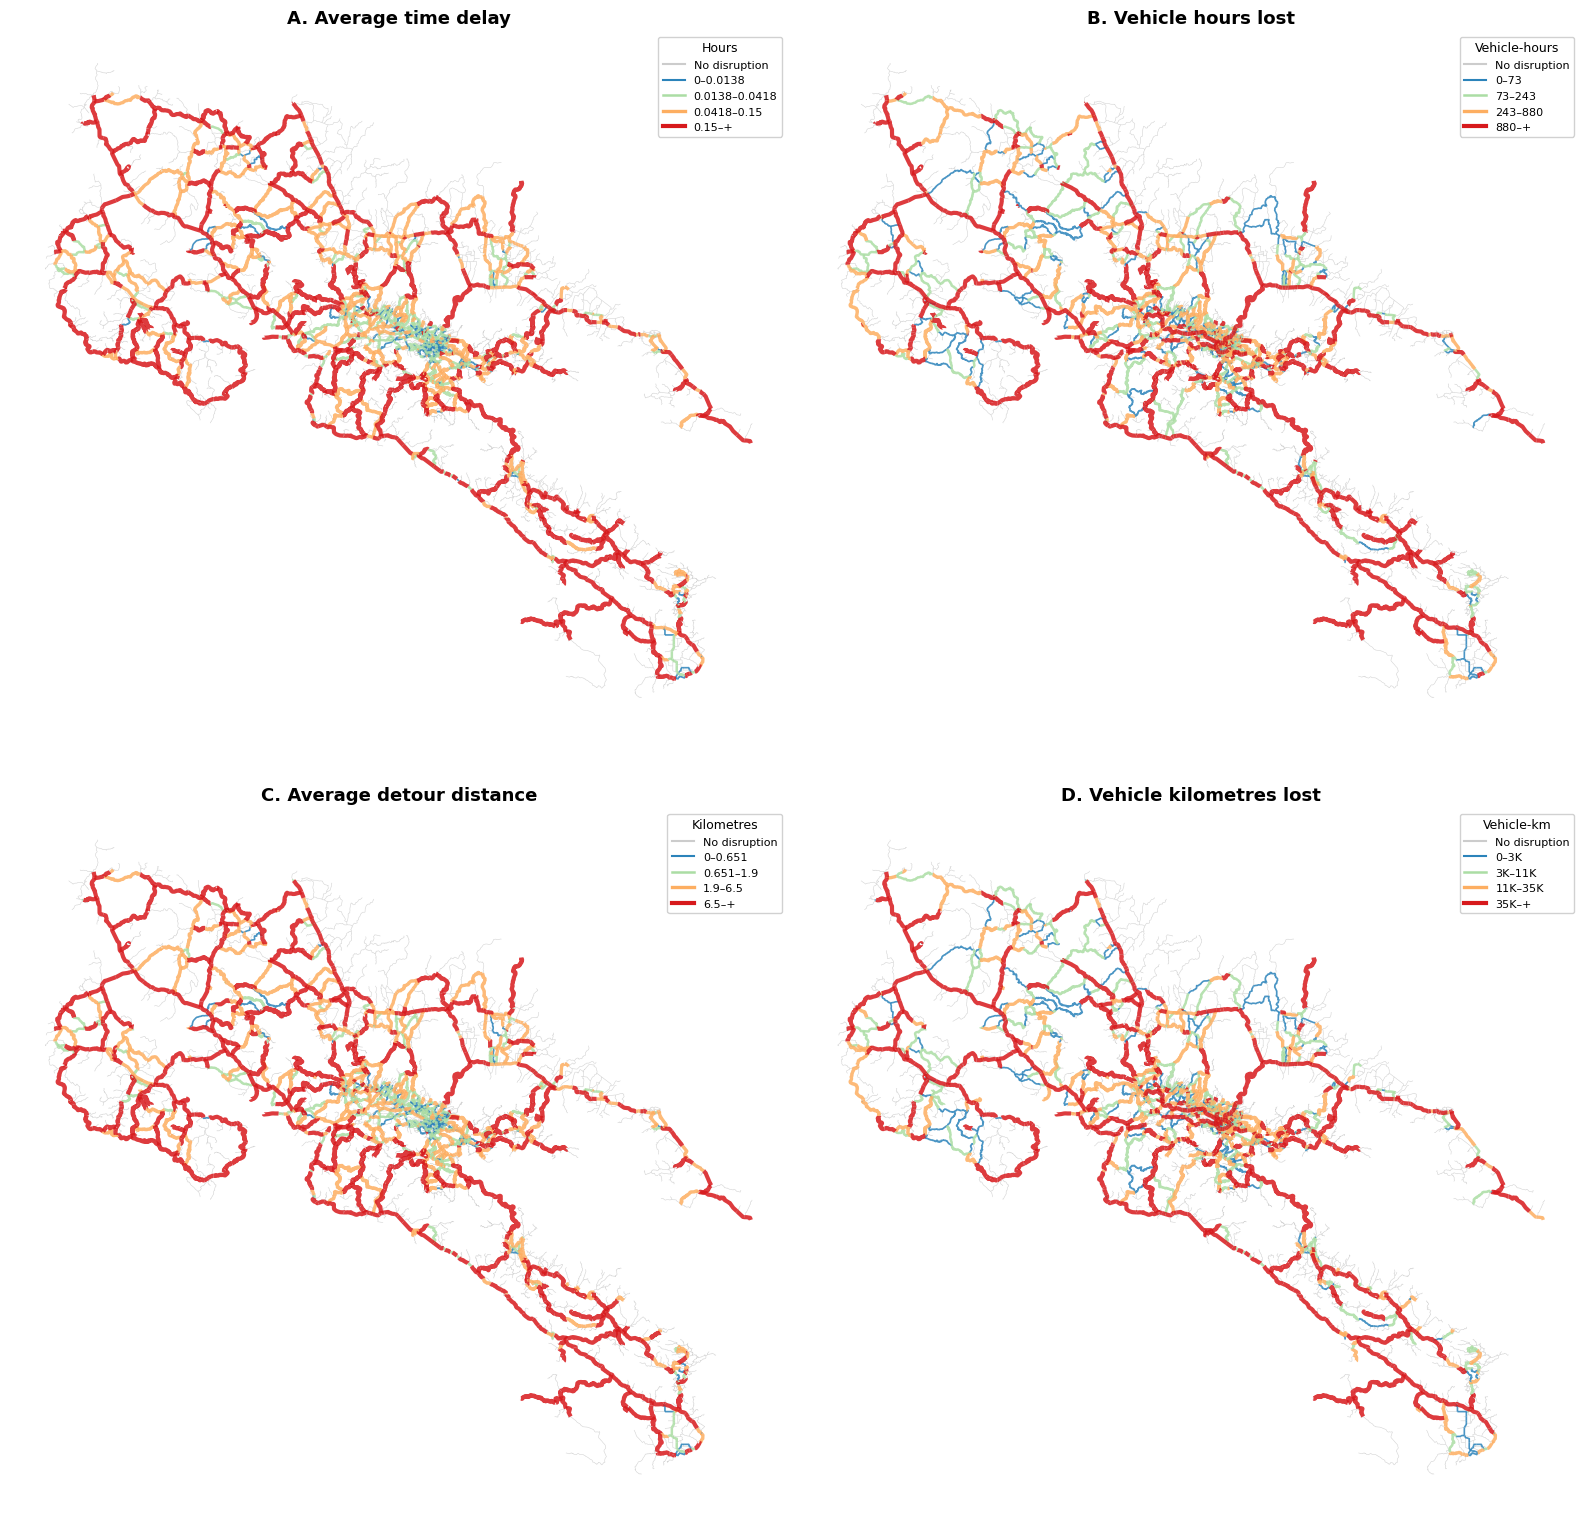

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(16, 16), facecolor="white")

panels = [
    ("average_time_disruption", "A. Average time delay", "Hours"),
    ("vhl", "B. Vehicle hours lost", "Vehicle-hours"),
    ("average_dist_disruption", "C. Average detour distance", "Kilometres"),
    ("vkl", "D. Vehicle kilometres lost", "Vehicle-km"),
]
for ax, (metric, title, legend_title) in zip(axes.ravel(), panels):
    plot_metric_panel(ax, gdf_web, metric, title, legend_title)

plt.tight_layout()
plt.savefig(figure_path / "SPOF_results_2x2.png", dpi=300, bbox_inches="tight")
plt.show()

## Save and reload physical_results to avoid rerunning the percolation analysis in future sessions

In [22]:
physical_results.to_file(physical_results_path, layer="criticality", driver="GPKG")

In [23]:
# Reopen
criticality_results = gpd.read_file(criticality_results_path)
gdf_results = gpd.read_file(criticality_results_path)
physical_results = gpd.read_file(physical_results_path, layer="criticality")

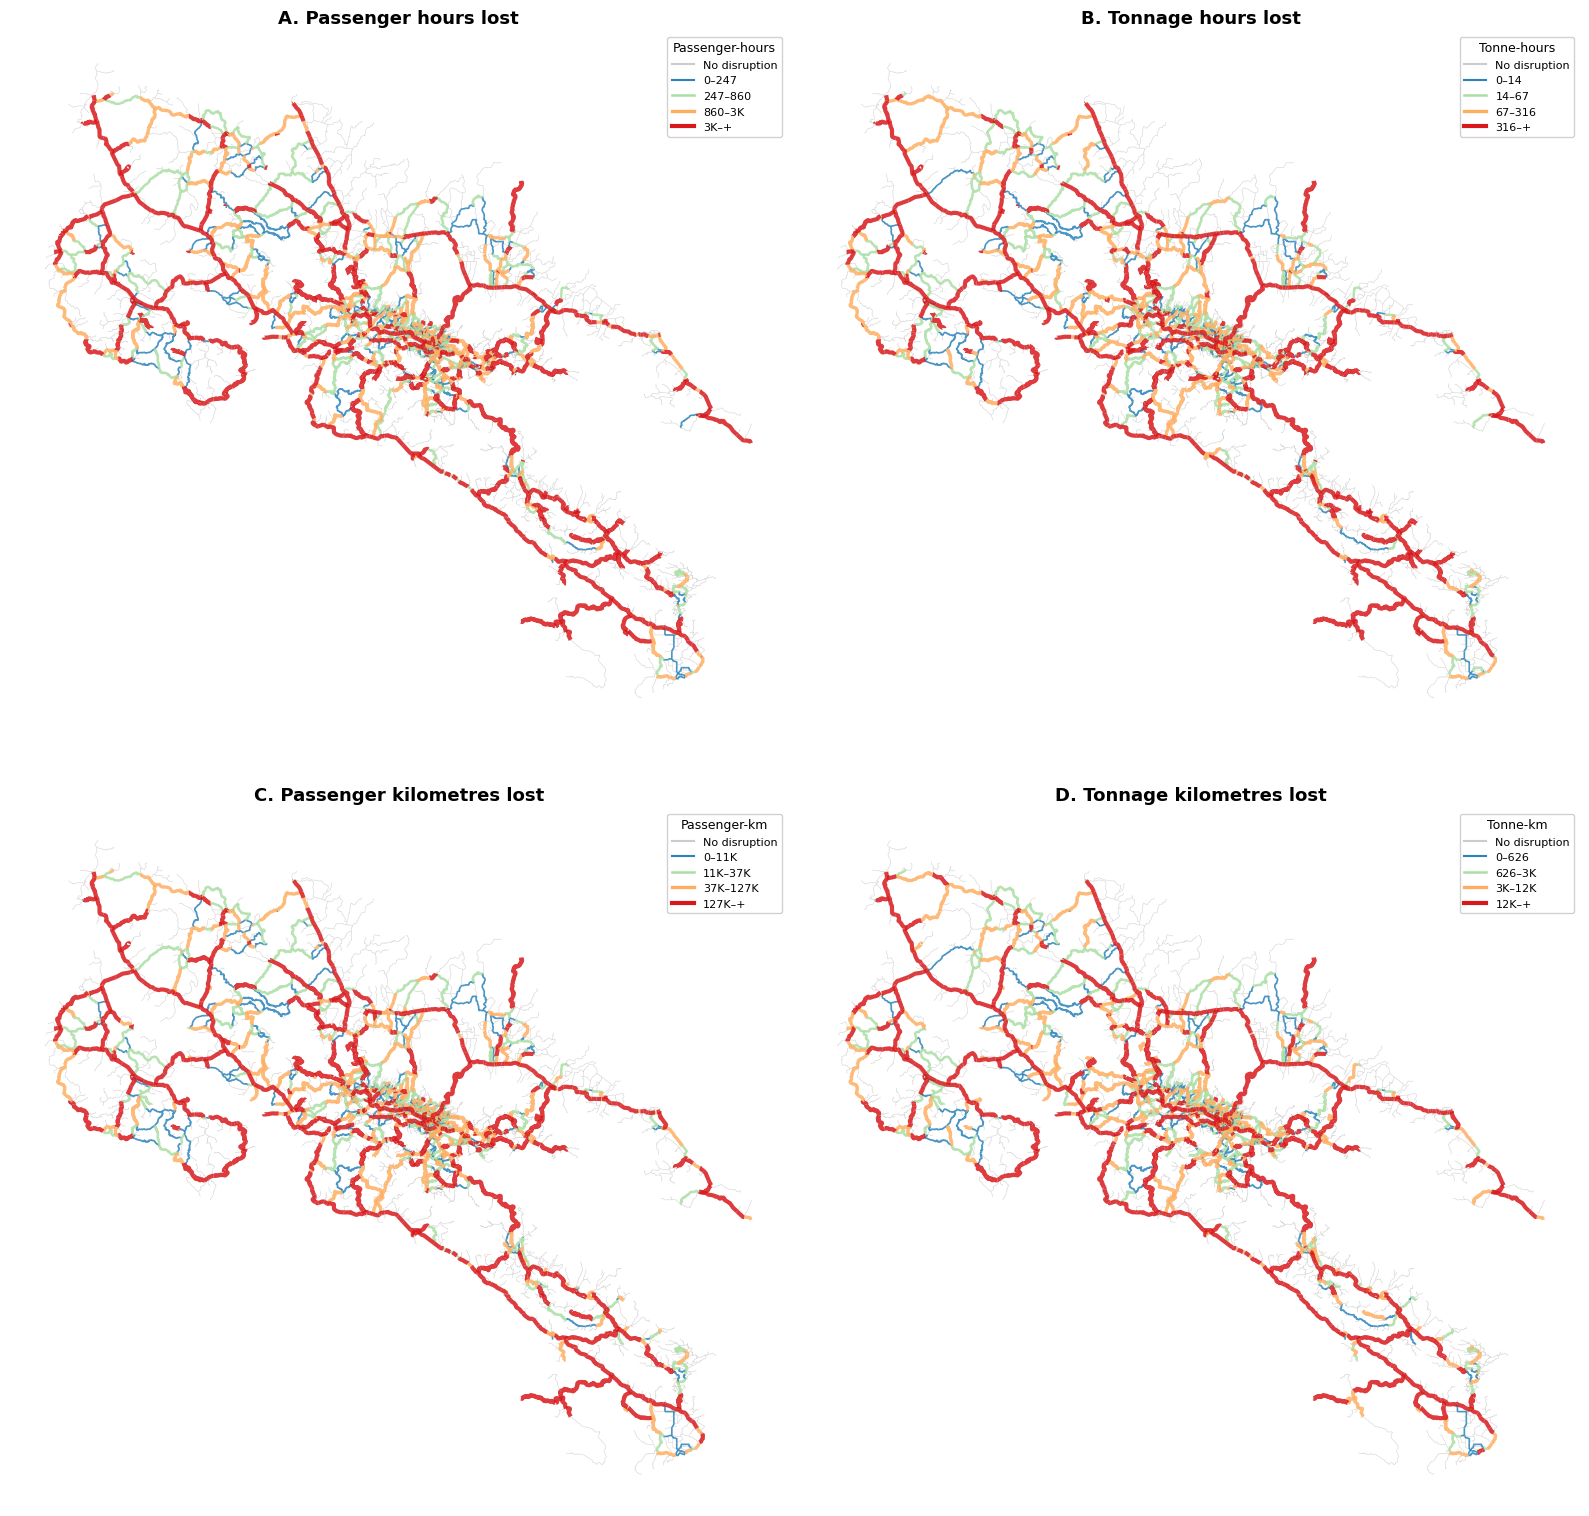

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(16, 16), facecolor="white")

panels = [
    ("phl", "A. Passenger hours lost", "Passenger-hours"),
    ("thl", "B. Tonnage hours lost", "Tonne-hours"),
    ("pkl", "C. Passenger kilometres lost", "Passenger-km"),
    ("tkl", "D. Tonnage kilometres lost", "Tonne-km"),
]
for ax, (metric, title, legend_title) in zip(axes.ravel(), panels):
    plot_metric_panel(ax, gdf_web, metric, title, legend_title)

plt.tight_layout()
plt.savefig(figure_path / "SPOF_PHL_THL_PKL_TKL.png", dpi=300, bbox_inches="tight")
plt.show()

Preparing PHL/TKL snapped-localities map...
Drawing PHL panel...
Drawing TKL panel...
Saving figure...


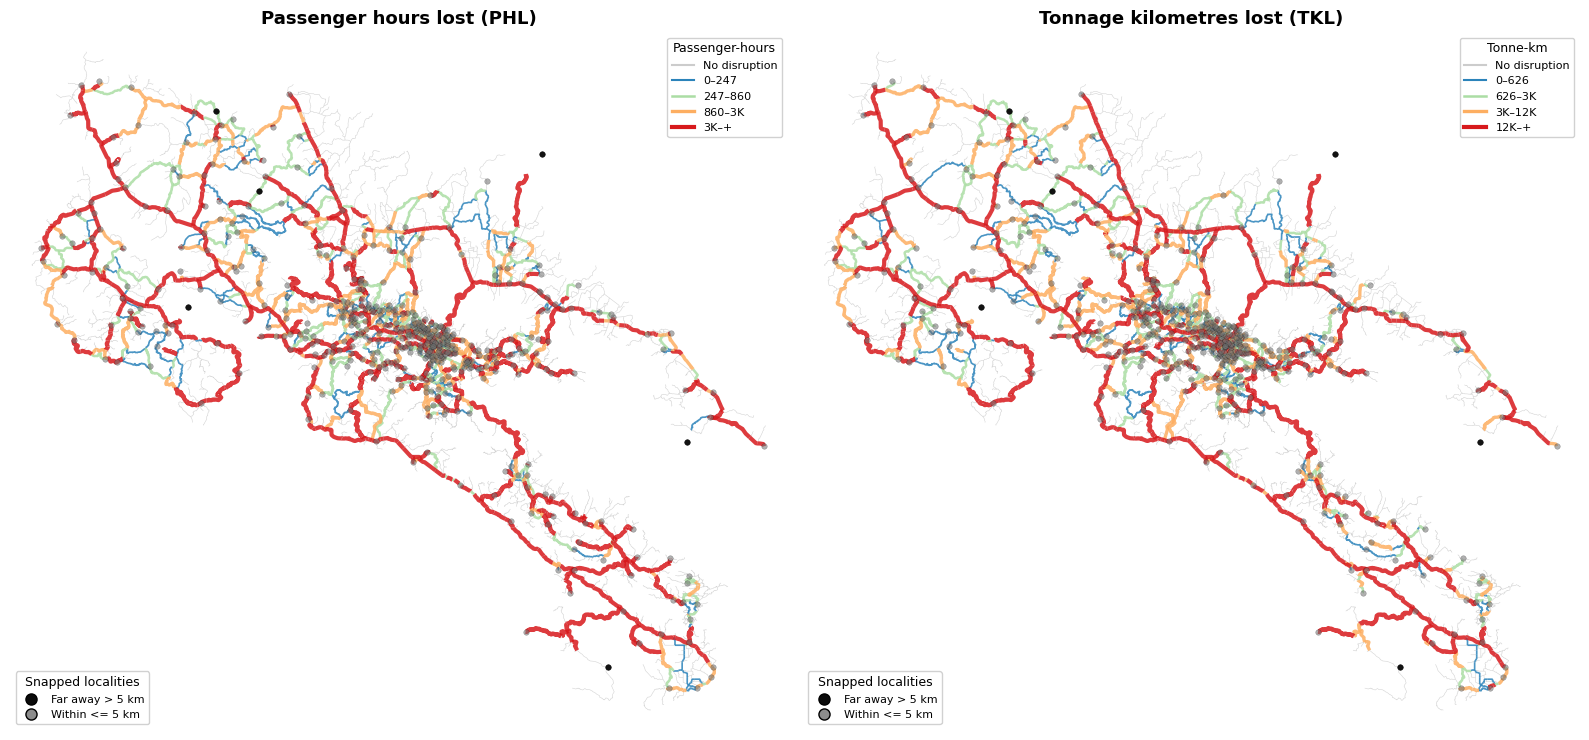

snap_far
Within network           487
Far away from network      6
Name: count, dtype: int64

In [25]:
## Plot map PHL and TKL with the localities that are snapped
# 1. Red - Far away from the network.
# 2. Blue - Within the network.

localities_web = OD_nodes.to_crs(3857)
within_localities = localities_web[~localities_web["snap_far"]]
far_localities = localities_web[localities_web["snap_far"]]
threshold_km = FAR_SNAP_WARN_M / 1000

print("Preparing PHL/TKL snapped-localities map...", flush=True)

combined_bounds = np.vstack([gdf_web.total_bounds, localities_web.total_bounds])
minx, miny = combined_bounds[:, :2].min(axis=0)
maxx, maxy = combined_bounds[:, 2:].max(axis=0)
pad_x = (maxx - minx) * 0.03
pad_y = (maxy - miny) * 0.03


def plot_metric_panel_without_basemap(ax, gdf_web, metric, title, legend_title):
    """Draw one criticality map panel without fetching remote basemap tiles."""
    breaks = METRIC_BREAKS[metric]
    classes, labels = classify_metric(gdf_web[metric], breaks)

    for i, label in enumerate(labels):
        subset = gdf_web[classes == label]
        if len(subset) == 0:
            continue
        subset.plot(ax=ax, color=CLASS_COLORS[i], linewidth=CLASS_WIDTHS[i],
                    alpha=0.85, zorder=2 + i)

    ax.set_xlim(minx - pad_x, maxx + pad_x)
    ax.set_ylim(miny - pad_y, maxy + pad_y)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_facecolor("#f7f7f7")

    handles = [Line2D([0], [0], color=CLASS_COLORS[i], lw=max(CLASS_WIDTHS[i], 1.5),
                      label=labels[i]) for i in range(len(labels))]
    criticality_legend = ax.legend(handles=handles, title=legend_title, loc="upper right",
                                   fontsize=8, title_fontsize=9, frameon=True,
                                   framealpha=0.9, facecolor="white", edgecolor="#cccccc")
    ax.add_artist(criticality_legend)


fig, axes = plt.subplots(1, 2, figsize=(16, 9), facecolor="white")
panels = [
    ("phl", "Passenger hours lost (PHL)", "Passenger-hours"),
    ("tkl", "Tonnage kilometres lost (TKL)", "Tonne-km"),
]

for ax, (metric, title, legend_title) in zip(axes, panels):
    print(f"Drawing {metric.upper()} panel...", flush=True)
    if not within_localities.empty:
        within_localities.plot(
            ax=ax,
            color="#707070CD",
            markersize=16,
            alpha=0.55,
            edgecolor="black",
            linewidth=0.2,
            zorder=8,
        )
    if not far_localities.empty:
        far_localities.plot(
            ax=ax,
            color="#060606",
            markersize=16,
            alpha=0.95,
            edgecolor="black",
            linewidth=0.4,
            zorder=9,
        )
    plot_metric_panel_without_basemap(ax, gdf_web, metric, title, legend_title)

    locality_legend = [
        Line2D([0], [0], marker="o", color="white", markerfacecolor="#0a0a0a",
               markeredgecolor="black", markersize=8, linestyle="None",
               label=f"Far away > {threshold_km:g} km"),
        Line2D([0], [0], marker="o", color="white", markerfacecolor="#707070CD",
               markeredgecolor="black", markersize=8, linestyle="None",
               label=f"Within <= {threshold_km:g} km"),
    ]
    ax.legend(handles=locality_legend, title="Snapped localities", loc="lower left",
              fontsize=8, title_fontsize=9, frameon=True, framealpha=0.9,
              facecolor="white", edgecolor="#cccccc")

plt.tight_layout()
print("Saving figure...", flush=True)
plt.savefig(figure_path / "SPOF_PHL_TKL_snapped_localities.png", dpi=300, bbox_inches="tight")
plt.show()

OD_nodes["snap_far"].value_counts().rename(index={False: "Within network", True: "Far away from network"})

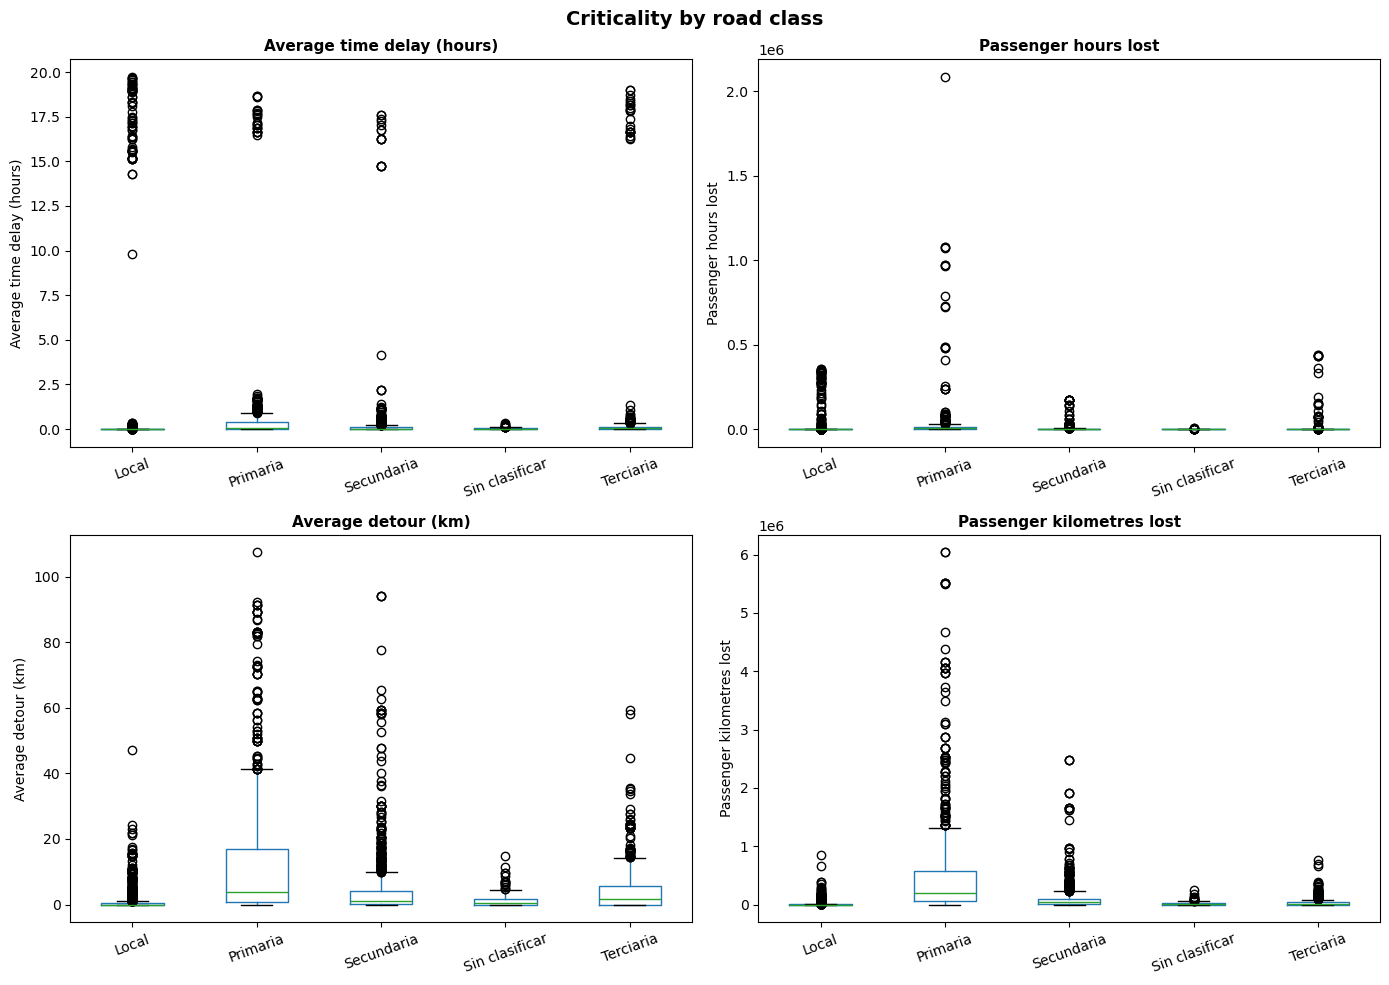

In [26]:
CLASS_ORDER = [c for c in ["Primaria", "Secundaria", "Terciaria", "Local", "Sin clasificar"]
               if c in physical_results["CLASE"].unique()]

fig, axes = plt.subplots(2, 2, figsize=(14, 10), facecolor="white")
panels = [
    ("average_time_disruption", "Average time delay (hours)"),
    ("phl", "Passenger hours lost"),
    ("average_dist_disruption", "Average detour (km)"),
    ("pkl", "Passenger kilometres lost"),
]
for ax, (metric, title) in zip(axes.ravel(), panels):
    physical_results.boxplot(column=metric, by="CLASE", ax=ax, grid=False)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=20)

fig.suptitle("Criticality by road class", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(figure_path / "SPOF_by_road_type_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

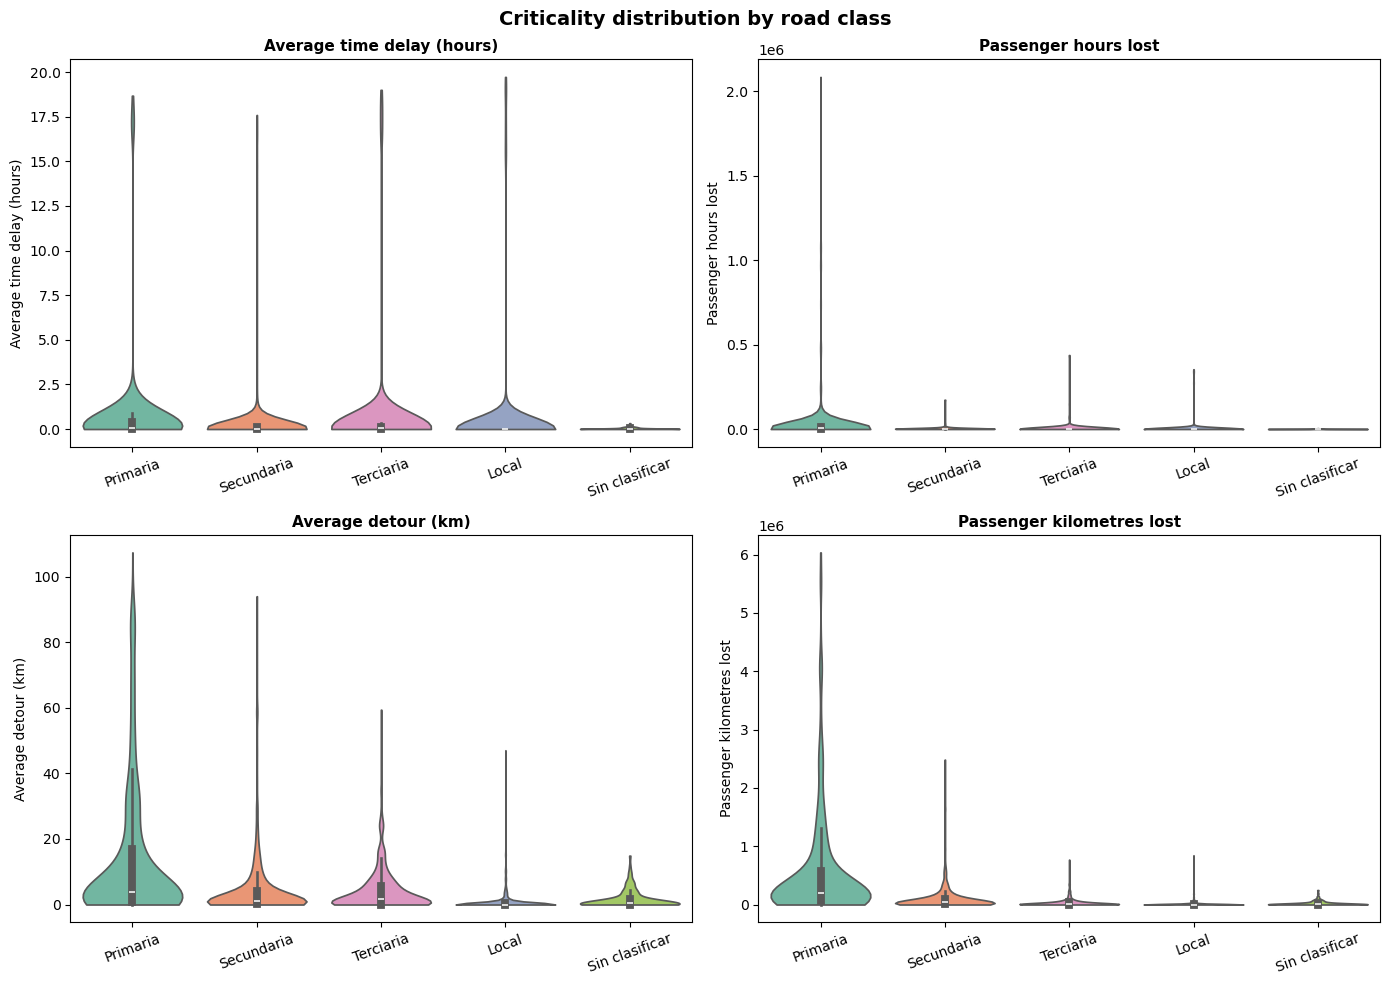

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), facecolor="white")
for ax, (metric, title) in zip(axes.ravel(), panels):
    sns.violinplot(data=physical_results, x="CLASE", y=metric, order=CLASS_ORDER,
                   ax=ax, cut=0, hue="CLASE", legend=False, palette="Set2")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=20)

fig.suptitle("Criticality distribution by road class", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(figure_path / "SPOF_by_road_type_violin.png", dpi=300, bbox_inches="tight")
plt.show()

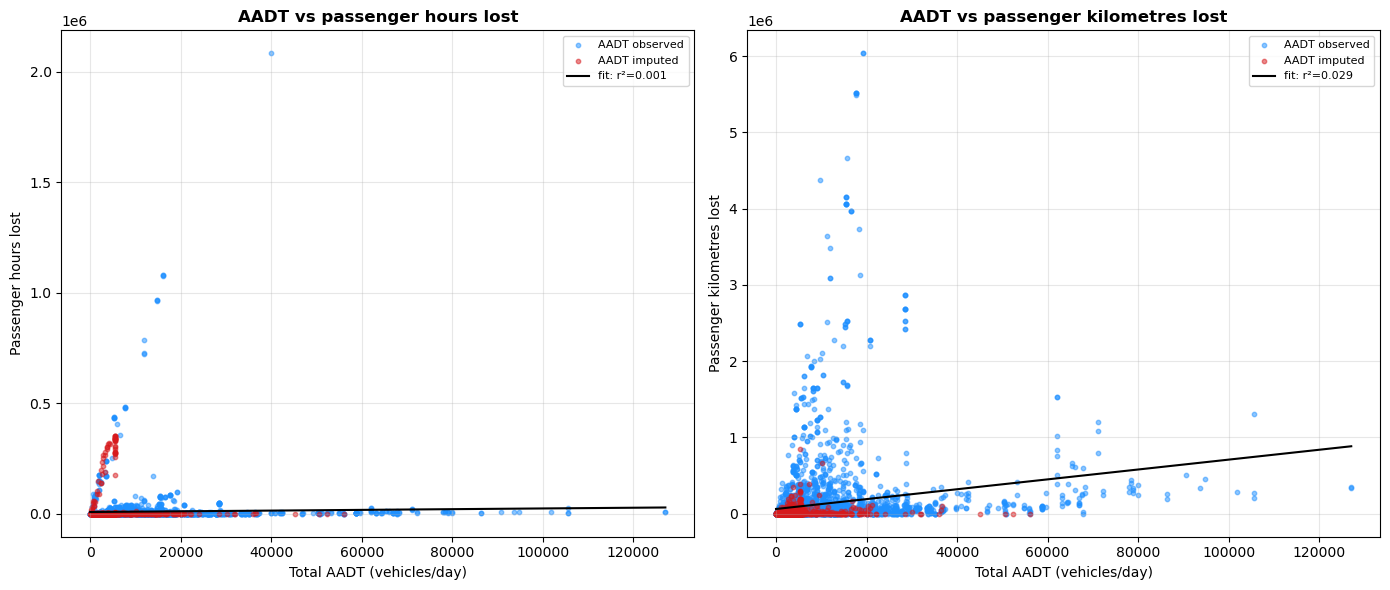

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), facecolor="white")

for ax, metric, label in [(ax1, "phl", "Passenger hours lost"),
                          (ax2, "pkl", "Passenger kilometres lost")]:
    observed = physical_results[~physical_results["aadt_imputed"]]
    imputed = physical_results[physical_results["aadt_imputed"]]

    ax.scatter(observed["total_aadt"], observed[metric], s=10, alpha=0.5,
               color="#1E90FF", label="AADT observed")
    ax.scatter(imputed["total_aadt"], imputed[metric], s=10, alpha=0.5,
               color="#d7191c", label="AADT imputed")

    valid = physical_results[["total_aadt", metric]].dropna()
    slope, intercept, r, p, se = stats.linregress(valid["total_aadt"], valid[metric])
    xs = np.linspace(valid["total_aadt"].min(), valid["total_aadt"].max(), 100)
    ax.plot(xs, intercept + slope * xs, color="black", lw=1.5,
            label=f"fit: r²={r ** 2:.3f}")

    ax.set_xlabel("Total AADT (vehicles/day)")
    ax.set_ylabel(label)
    ax.set_title(f"AADT vs {label.lower()}", fontsize=12, fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(figure_path / "SPOF_AADT_vs_criticality.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Save criticality results

In [29]:
preferred_columns = [
    # identity / topology
    "id", "physical_edge_id", "source_part_id", "from_id", "to_id", "direction_side",
    # source attributes
    "ID_TRAMO", "TRAMO_UID", "ID_RUTA", "NOMBRE", "CLASE", "ADMIN",
    "NODO_INI", "NODO_FIN", "DIRECCION",
    # network attributes
    "road_length", "speed", "speed_source", "fft",
    # traffic
    "motorcycles", "pickup_trucks", "passenger_cars", "buses",
    "light_trucks", "medium_trucks", "heavy_trucks", "total_aadt",
    "aadt_imputed", "direction_imputed",
    # disruption
    "pct_isolated", "pct_unaffected", "pct_delayed",
    "average_time_disruption", "average_dist_disruption",
    "distance_disruption", "time_disruption",
    # criticality
    "vhl", "vkl", "phl", "thl", "pkl", "tkl",
    "geometry",
]

# Filtering silently drops unknown names, so assert first rather than shipping a
# near-empty table if the schema ever drifts.
absent = [c for c in preferred_columns if c not in gdf_results.columns]
assert not absent, f"Expected columns absent from results: {absent}"

results = gdf_results[preferred_columns].copy()
results.to_file(criticality_results_path, layer="criticality_results",
                driver="GPKG", index=False)
print(f"Saved → {criticality_results_path}")

Saved → /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/gpkg/travel_disruptions/criticality_results.gpkg


In [30]:
# Re-open and verify the written layer.
check = gpd.read_file(criticality_results_path, layer="criticality_results")

assert len(check) == len(results), f"row count mismatch: {len(check)} vs {len(results)}"
assert check.crs.to_epsg() == WORKING_EPSG, f"CRS mismatch: {check.crs}"
assert set(check.geom_type.unique()) == {"LineString"}, "unexpected geometry type"
for col in ["id", "physical_edge_id", "average_time_disruption", "phl", "tkl"]:
    assert check[col].notna().all(), f"{col} has nulls after round-trip"
assert check["id"].is_unique, "duplicate edge ids in output"

size_mb = criticality_results_path.stat().st_size / 1e6

print("Output manifest")
print("=" * 60)
print(f"Path      : {criticality_results_path.absolute()}")
print(f"Layer     : criticality_results")
print(f"Rows      : {len(check):,}")
print(f"Columns   : {len(check.columns)}")
print(f"CRS       : {check.crs}")
print(f"Size      : {size_mb:.1f} MB")
print("\nFigures")
for name in ["SPOF_results_2x2.png", "SPOF_PHL_THL_PKL_TKL.png",
             "SPOF_PHL_TKL_snapped_localities.png",
             "SPOF_by_road_type_boxplot.png", "SPOF_by_road_type_violin.png",
             "SPOF_AADT_vs_criticality.png"]:
    p = figure_path / name
    print(f"  {'OK ' if p.exists() else 'MISSING'} {name}")

Output manifest
Path      : /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/gpkg/travel_disruptions/criticality_results.gpkg
Layer     : criticality_results
Rows      : 9,764
Columns   : 43
CRS       : EPSG:8908
Size      : 91.8 MB

Figures
  OK  SPOF_results_2x2.png
  OK  SPOF_PHL_THL_PKL_TKL.png
  OK  SPOF_PHL_TKL_snapped_localities.png
  OK  SPOF_by_road_type_boxplot.png
  OK  SPOF_by_road_type_violin.png
  OK  SPOF_AADT_vs_criticality.png


## 10. Summary statistics
Reported per **physical road** so bidirectional roads are not double counted.The Serbian version of this notebook compared results against Serbian national transportstatistics (H1 2025 passenger-km and tonne-km). Those denominators are not applicable to CostaRica and have been removed rather than reused — substituting cited INEC / MOPT / CONAVI figuresis a separate task.

In [31]:
total_sections = len(physical_results)
print("=" * 64)
print(f"SPOF CRITICALITY SUMMARY — {total_sections:,} physical roads")
print("=" * 64)

delay_min = physical_results["average_time_disruption"] * 60
buckets = [
    ("No/low delay (<5 min)", (delay_min < 5).sum()),
    ("5–15 min", ((delay_min >= 5) & (delay_min < 15)).sum()),
    ("15–30 min", ((delay_min >= 15) & (delay_min < 30)).sum()),
    ("30–60 min", ((delay_min >= 30) & (delay_min < 60)).sum()),
    ("60+ min", (delay_min >= 60).sum()),
]
print("\nAverage delay when the road fails:")
for name, n in buckets:
    print(f"  {name:24} {n:5,} ({n / total_sections * 100:5.1f}%)")

isolating = physical_results[physical_results["pct_isolated"] > 0]
print(f"\nRoads whose failure isolates at least one OD pair: {len(isolating):,} "
      f"({len(isolating) / total_sections * 100:.1f}%)")

SPOF CRITICALITY SUMMARY — 5,012 physical roads

Average delay when the road fails:
  No/low delay (<5 min)    3,923 ( 78.3%)
  5–15 min                   559 ( 11.2%)
  15–30 min                  210 (  4.2%)
  30–60 min                  123 (  2.5%)
  60+ min                    197 (  3.9%)

Roads whose failure isolates at least one OD pair: 130 (2.6%)


In [32]:
id_cols = ["physical_edge_id", "NOMBRE", "CLASE", "ID_TRAMO",
           "total_aadt", "average_time_disruption", "average_dist_disruption",
           "phl", "pkl", "thl", "tkl"]

print("Top 10 roads by passenger hours lost")
print(physical_results.nlargest(10, "phl")[id_cols].to_string(index=False))

print("\nTop 10 roads by tonnage kilometres lost")
print(physical_results.nlargest(10, "tkl")[id_cols].to_string(index=False))

Top 10 roads by passenger hours lost
 physical_edge_id               NOMBRE    CLASE  ID_TRAMO  total_aadt  average_time_disruption  average_dist_disruption          phl           pkl           thl           tkl
              655  Ruta Nacional No. 3 Primaria     620.0     39850.0                16.485908                 0.576367 2.083693e+06  72848.405074 187400.261219   6551.736299
             2186 Ruta Nacional No. 17 Primaria    2119.0     16091.0                18.675857                 3.985222 1.078942e+06 230234.224940  76451.486215  16313.903331
             2187 Ruta Nacional No. 17 Primaria    2120.0     16091.0                18.675857                 1.793041 1.078942e+06 103587.543611  76451.486215   7339.991147
             1237 Ruta Nacional No. 17 Primaria    1168.0     16091.0                18.585753                15.104170 1.073736e+06 872598.091131  76082.637200  61830.429029
             2199 Ruta Nacional No. 32 Primaria    2132.0     14779.0                17.

In [33]:
print("Criticality by road class (physical roads)")
class_summary = physical_results.groupby("CLASE").agg(
    roads=("physical_edge_id", "count"),
    length_km=("road_length", "sum"),
    mean_delay_min=("average_time_disruption", lambda s: s.mean() * 60),
    mean_detour_km=("average_dist_disruption", "mean"),
    mean_aadt=("total_aadt", "mean"),
    total_phl=("phl", "sum"),
    total_tkl=("tkl", "sum"),
).reindex(CLASS_ORDER)
print(class_summary.round(1).to_string())

Criticality by road class (physical roads)
                roads  length_km  mean_delay_min  mean_detour_km  mean_aadt   total_phl   total_tkl
CLASE                                                                                              
Primaria          717     2030.8            47.4            13.9    19917.2  21511956.5  86340711.1
Secundaria       1247     2755.9            17.3             4.4    11511.4   5012339.5  10134776.4
Terciaria         726     3101.9            38.4             4.3     2853.3   4800736.3   1685557.9
Local            2199     6447.0            31.2             0.7     4675.4  13613489.6   1151080.9
Sin clasificar    123      475.0             2.0             1.6     4285.8     50475.0    188844.5


## Roads that are more critical than their traffic volume alone would suggest.

In [34]:
valid = physical_results[["total_aadt", "phl"]].dropna()
slope, intercept, r, p, se = stats.linregress(valid["total_aadt"], valid["phl"])
print(f"PHL ~ AADT : r² = {r ** 2:.3f}, slope = {slope:.2f}, p = {p:.3g}")

physical_results = physical_results.copy()
physical_results["phl_expected"] = intercept + slope * physical_results["total_aadt"]
physical_results["phl_residual"] = physical_results["phl"] - physical_results["phl_expected"]

print("\nMost critical relative to their traffic volume (largest positive residual):")
print(physical_results.nlargest(10, "phl_residual")[
    ["NOMBRE", "CLASE", "total_aadt", "phl", "phl_residual"]
].to_string(index=False))

print("\nExamples")
for _, row in physical_results.nlargest(3, "phl").iterrows():
    print(f"\n--- {row['NOMBRE']} ({row['CLASE']}) ---")
    print(f"  Nodes        : {row['NODO_INI']:.0f} → {row['NODO_FIN']:.0f}"
          if pd.notna(row["NODO_INI"]) else "  Nodes        : n/a")
    print(f"  AADT         : {row['total_aadt']:,.0f}")
    print(f"  Avg delay    : {row['average_time_disruption'] * 60:.0f} min")
    print(f"  Avg detour   : {row['average_dist_disruption']:.1f} km")
    print(f"  PHL / PKL    : {row['phl']:,.0f} / {row['pkl']:,.0f}")
    print(f"  THL / TKL    : {row['thl']:,.0f} / {row['tkl']:,.0f}")

PHL ~ AADT : r² = 0.001, slope = 0.16, p = 0.0379

Most critical relative to their traffic volume (largest positive residual):
              NOMBRE    CLASE  total_aadt          phl  phl_residual
 Ruta Nacional No. 3 Primaria     39850.0 2.083693e+06  2.069616e+06
Ruta Nacional No. 17 Primaria     16091.0 1.078942e+06  1.068704e+06
Ruta Nacional No. 17 Primaria     16091.0 1.078942e+06  1.068704e+06
Ruta Nacional No. 17 Primaria     16091.0 1.073736e+06  1.063498e+06
Ruta Nacional No. 32 Primaria     14779.0 9.677385e+05  9.577126e+05
Ruta Nacional No. 32 Primaria     14779.0 9.677385e+05  9.577126e+05
Ruta Nacional No. 32 Primaria     14779.0 9.649578e+05  9.549318e+05
Ruta Nacional No. 32 Primaria     11918.0 7.845509e+05  7.749873e+05
Ruta Nacional No. 32 Primaria     11790.0 7.260954e+05  7.165524e+05
Ruta Nacional No. 32 Primaria     11790.0 7.241407e+05  7.145978e+05

Examples

--- Ruta Nacional No. 3 (Primaria) ---
  Nodes        : 2415 → 2060
  AADT         : 39,850
  Avg delay

Assigning baseline OD demand: 100%|██████████| 485/485 [00:05<00:00, 81.46it/s]


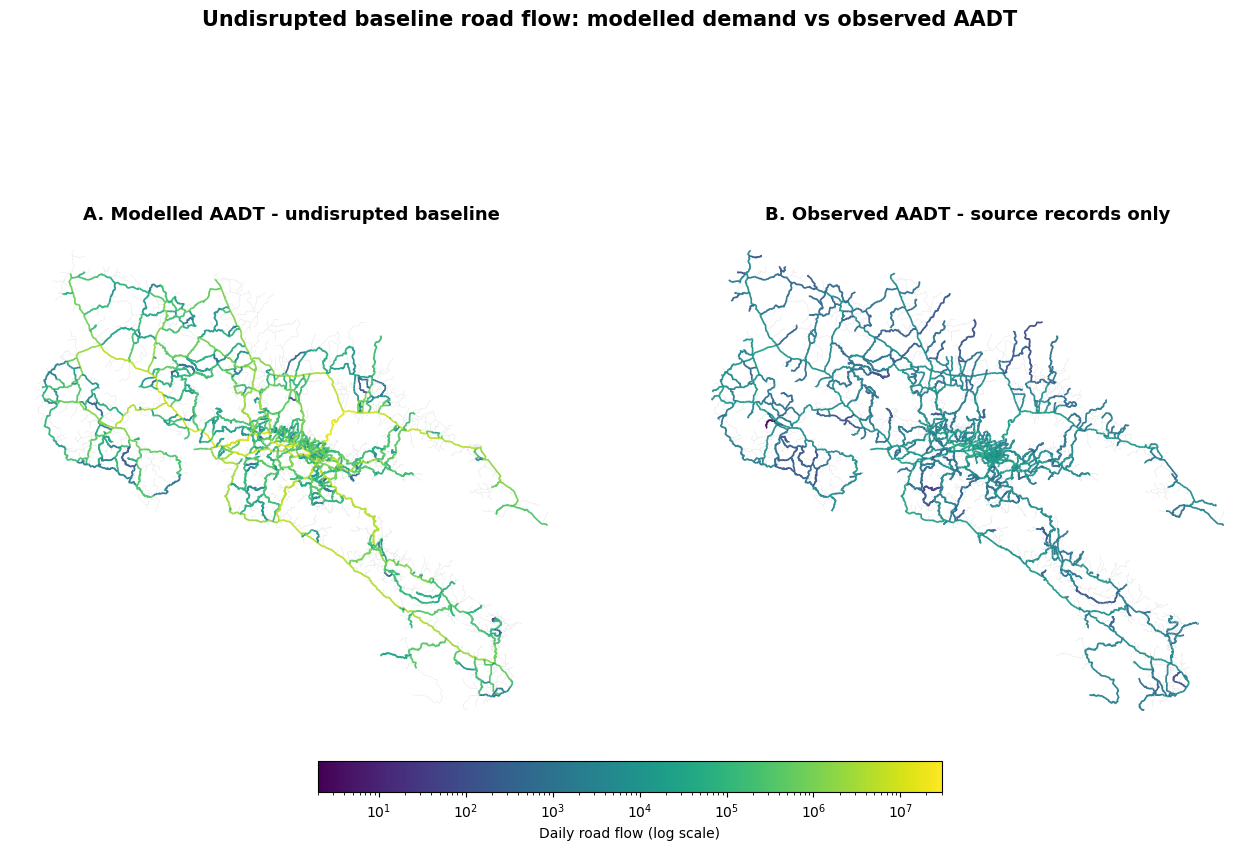

Modelled AADT panel: 3,056 roads with positive assigned flow, max 30,038,676, sum 4,851,947,168
Observed AADT panel: 3,140 roads with observed AADT, max 127,048, sum 33,055,633


In [35]:
# Undisrupted baseline assignment: modelled gravity demand vs observed AADT.
# Panel A assigns the synthetic OD demand to shortest paths in the intact network.
# Panel B shows only source-observed AADT; roads with imputed AADT stay as grey context.
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LogNorm

vertex_ids = grouped_OD["vertex_id"].to_numpy(dtype=int)
demand_array = np.asarray(demand, dtype=float)
modelled_directed_aadt = np.zeros(graph.ecount(), dtype=float)

for o_pos, o_vertex in enumerate(tqdm(vertex_ids, desc="Assigning baseline OD demand")):
    dest_pos = np.flatnonzero(demand_array[o_pos] > 0)
    if len(dest_pos) == 0:
        continue
    paths = graph.get_shortest_paths(
        int(o_vertex),
        to=vertex_ids[dest_pos].tolist(),
        weights="fft",
        output="epath",
    )
    for d_pos, path in zip(dest_pos, paths):
        if path:
            modelled_directed_aadt[path] += demand_array[o_pos, d_pos]

modelled_by_physical = (
    pd.DataFrame({
        "physical_edge_id": graph.es["physical_edge_id"],
        "modelled_aadt": modelled_directed_aadt,
    })
    .groupby("physical_edge_id", as_index=False)["modelled_aadt"]
    .sum()
)

aadt_compare = physical_results.merge(modelled_by_physical, on="physical_edge_id", how="left")
aadt_compare["modelled_aadt"] = aadt_compare["modelled_aadt"].fillna(0.0)
aadt_compare["observed_aadt"] = aadt_compare["total_aadt"].where(
    ~aadt_compare["aadt_imputed"].astype(bool)
)
aadt_compare = gpd.GeoDataFrame(aadt_compare, geometry="geometry", crs=physical_results.crs)
aadt_compare_web = aadt_compare.to_crs(3857)

positive_values = pd.concat([
    aadt_compare["modelled_aadt"].where(aadt_compare["modelled_aadt"] > 0),
    aadt_compare["observed_aadt"],
]).dropna()
vmin = max(1.0, float(positive_values.min()))
vmax = float(positive_values.max())
norm = LogNorm(vmin=vmin, vmax=vmax)
cmap = "viridis"


def plot_baseline_aadt_panel(ax, gdf, column, mask, title):
    gdf.plot(ax=ax, color="#d9d9d9", linewidth=0.35, alpha=0.65, zorder=1)
    subset = gdf.loc[mask & gdf[column].notna() & (gdf[column] > 0)]
    if len(subset):
        subset.plot(
            ax=ax,
            column=column,
            cmap=cmap,
            norm=norm,
            linewidth=1.25,
            alpha=0.95,
            zorder=2,
        )
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_aspect("equal")
    ax.axis("off")
    return len(subset), subset[column].sum(), subset[column].max() if len(subset) else 0.0


fig, axes = plt.subplots(1, 2, figsize=(16, 9), facecolor="white")

modelled_stats = plot_baseline_aadt_panel(
    axes[0],
    aadt_compare_web,
    "modelled_aadt",
    aadt_compare_web["modelled_aadt"] > 0,
    "A. Modelled AADT - undisrupted baseline",
)
observed_stats = plot_baseline_aadt_panel(
    axes[1],
    aadt_compare_web,
    "observed_aadt",
    aadt_compare_web["observed_aadt"].notna(),
    "B. Observed AADT - source records only",
)

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, orientation="horizontal", fraction=0.045, pad=0.04)
cbar.set_label("Daily road flow (log scale)")

fig.suptitle("Undisrupted baseline road flow: modelled demand vs observed AADT",
             fontsize=15, fontweight="bold")
plt.savefig(figure_path / "AADT_modelled_vs_observed_undisrupted.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Modelled AADT panel: "
      f"{modelled_stats[0]:,} roads with positive assigned flow, "
      f"max {modelled_stats[2]:,.0f}, sum {modelled_stats[1]:,.0f}")
print("Observed AADT panel: "
      f"{observed_stats[0]:,} roads with observed AADT, "
      f"max {observed_stats[2]:,.0f}, sum {observed_stats[1]:,.0f}")

## Reproduce with aadt*speed instead of aadt: Roads that are more critical than their traffic volume alone would suggest.

In [36]:
physical_results['aadt_speed'] = physical_results['total_aadt']* physical_results['speed']

# Roads that are more critical than their traffic volume alone would suggest.
valid = physical_results[["aadt_speed", "phl"]].dropna()
slope, intercept, r, p, se = stats.linregress(valid["aadt_speed"], valid["phl"])
print(f"PHL ~ AADT : r² = {r ** 2:.3f}, slope = {slope:.2f}, p = {p:.3g}")

physical_results["phl_expected_speed"] = intercept + slope * physical_results["aadt_speed"]
physical_results["phl_residual_speed"] = physical_results["phl"] - physical_results["phl_expected_speed"]

print("\nMost critical relative to their traffic volume (largest positive residual):")
print(physical_results.nlargest(10, "phl_residual_speed")[
    ["NOMBRE", "CLASE", "aadt_speed", "phl", "phl_residual_speed"]
].to_string(index=False))

print("\nExamples")
for _, row in physical_results.nlargest(3, "phl").iterrows():
    print(f"\n--- {row['NOMBRE']} ({row['CLASE']}) ---")
    print(f"  Nodes        : {row['NODO_INI']:.0f} → {row['NODO_FIN']:.0f}"
          if pd.notna(row["NODO_INI"]) else "  Nodes        : n/a")
    print(f"  aadt_speed         : {row['aadt_speed']:,.0f}")
    print(f"  Avg delay    : {row['average_time_disruption'] * 60:.0f} min")
    print(f"  Avg detour   : {row['average_dist_disruption']:.1f} km")
    print(f"  PHL / PKL    : {row['phl']:,.0f} / {row['pkl']:,.0f}")
    print(f"  THL / TKL    : {row['thl']:,.0f} / {row['tkl']:,.0f}")

PHL ~ AADT : r² = 0.002, slope = 0.00, p = 0.00601

Most critical relative to their traffic volume (largest positive residual):
              NOMBRE    CLASE  aadt_speed          phl  phl_residual_speed
 Ruta Nacional No. 3 Primaria   1594000.0 2.083693e+06        2.070834e+06
Ruta Nacional No. 17 Primaria    965460.0 1.078942e+06        1.068122e+06
Ruta Nacional No. 17 Primaria    965460.0 1.078942e+06        1.068122e+06
Ruta Nacional No. 17 Primaria    965460.0 1.073736e+06        1.062916e+06
Ruta Nacional No. 32 Primaria   1182320.0 9.677385e+05        9.562148e+05
Ruta Nacional No. 32 Primaria   1182320.0 9.677385e+05        9.562148e+05
Ruta Nacional No. 32 Primaria   1182320.0 9.649578e+05        9.534341e+05
Ruta Nacional No. 32 Primaria    953440.0 7.845509e+05        7.737699e+05
Ruta Nacional No. 32 Primaria    943200.0 7.260954e+05        7.153475e+05
Ruta Nacional No. 32 Primaria    943200.0 7.241407e+05        7.133929e+05

Examples

--- Ruta Nacional No. 3 (Primaria) -

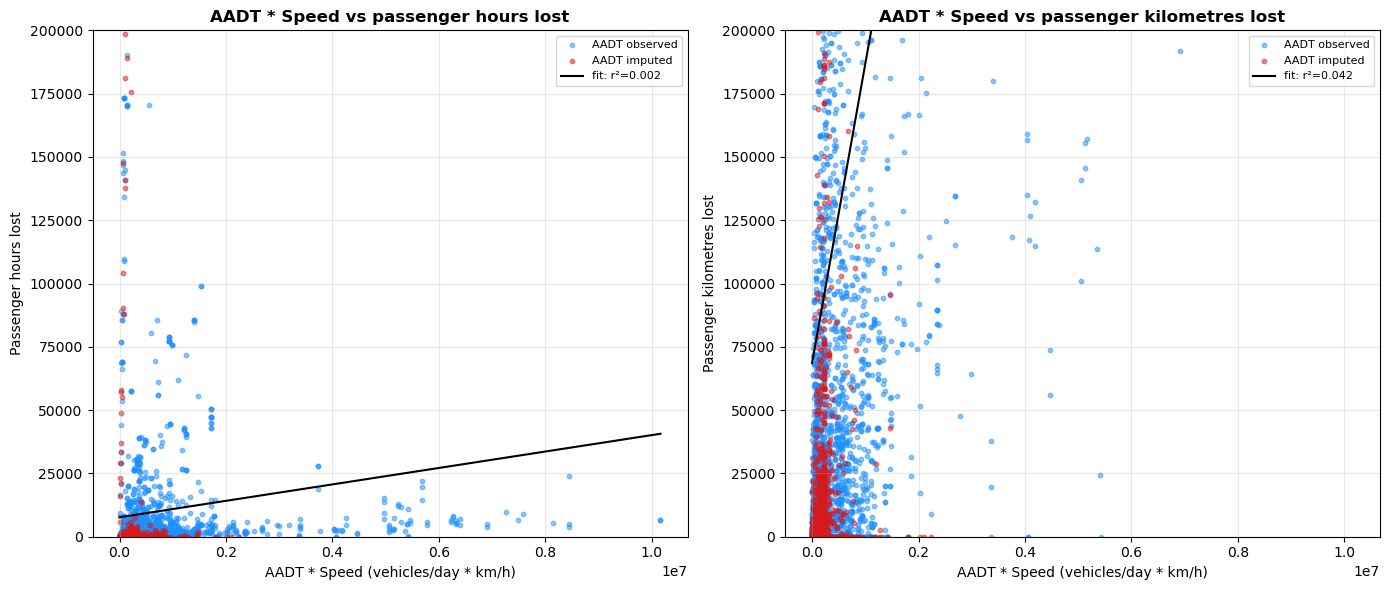

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), facecolor="white")

for ax, metric, label in [(ax1, "phl", "Passenger hours lost"),
                          (ax2, "pkl", "Passenger kilometres lost")]:
    observed = physical_results[~physical_results["aadt_imputed"]]
    imputed = physical_results[physical_results["aadt_imputed"]]

    ax.scatter(observed["aadt_speed"], observed[metric], s=10, alpha=0.5,
               color="#1E90FF", label="AADT observed")
    ax.scatter(imputed["aadt_speed"], imputed[metric], s=10, alpha=0.5,
               color="#d7191c", label="AADT imputed")

    valid = physical_results[["aadt_speed", metric]].dropna()
    slope, intercept, r, p, se = stats.linregress(valid["aadt_speed"], valid[metric])
    xs = np.linspace(valid["aadt_speed"].min(), valid["aadt_speed"].max(), 100)
    ax.plot(xs, intercept + slope * xs, color="black", lw=1.5,
            label=f"fit: r²={r ** 2:.3f}")

    ax.set_xlabel("AADT * Speed (vehicles/day * km/h)")
    ax.set_ylabel(label)
    ax.set_title(f"AADT * Speed vs {label.lower()}", fontsize=12, fontweight="bold")
    ax.set_ylim(top=200000, bottom=0)

    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(figure_path / "SPOF_AADT_speed_vs_criticality.png", dpi=300, bbox_inches="tight")
plt.show()

## AADT * Speed * Lenght Roads that are more critical than their traffic volume alone would suggest.

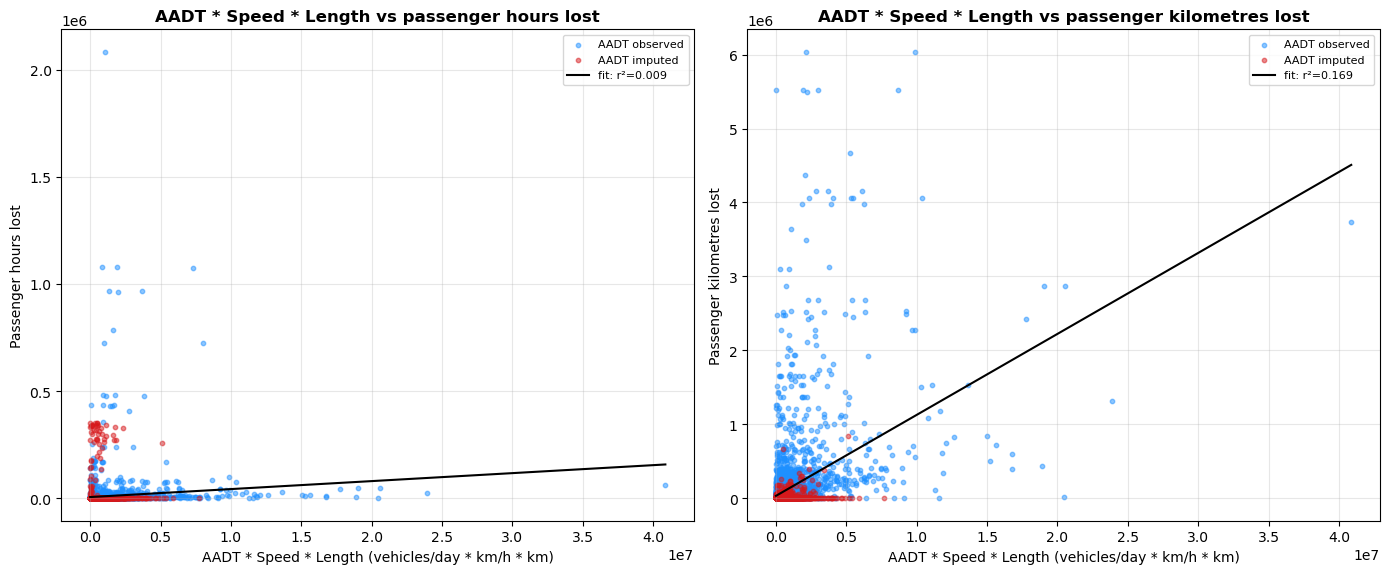

In [38]:
physical_results['aadt_speed_length'] = physical_results['aadt_speed']* physical_results['road_length']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), facecolor="white")

for ax, metric, label in [(ax1, "phl", "Passenger hours lost"),
                          (ax2, "pkl", "Passenger kilometres lost")]:
    observed = physical_results[~physical_results["aadt_imputed"]]
    imputed = physical_results[physical_results["aadt_imputed"]]

    ax.scatter(observed["aadt_speed_length"], observed[metric], s=10, alpha=0.5,
               color="#1E90FF", label="AADT observed")
    ax.scatter(imputed["aadt_speed_length"], imputed[metric], s=10, alpha=0.5,
               color="#d7191c", label="AADT imputed")

    valid = physical_results[["aadt_speed_length", metric]].dropna()
    slope, intercept, r, p, se = stats.linregress(valid["aadt_speed_length"], valid[metric])
    xs = np.linspace(valid["aadt_speed_length"].min(), valid["aadt_speed_length"].max(), 100)
    ax.plot(xs, intercept + slope * xs, color="black", lw=1.5,
            label=f"fit: r²={r ** 2:.3f}")

    ax.set_xlabel("AADT * Speed * Length (vehicles/day * km/h * km)")
    ax.set_ylabel(label)
    ax.set_title(f"AADT * Speed * Length vs {label.lower()}", fontsize=12, fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(figure_path / "SPOF_AADT_speed_length_vs_criticality.png", dpi=300, bbox_inches="tight")
plt.show()

In [39]:
#PHL
#Reproduce with aadt*speed*length instead of aadt:

# Roads that are more critical than their traffic volume alone would suggest.
valid = physical_results[["aadt_speed_length", "phl"]].dropna()
slope, intercept, r, p, se = stats.linregress(valid["aadt_speed_length"], valid["phl"])
print(f"PHL ~ AADT * Speed * Length : r² = {r ** 2:.3f}, slope = {slope:.2f}, p = {p:.3g}")

physical_results["phl_expected_speed_length"] = intercept + slope * physical_results["aadt_speed_length"]
physical_results["phl_residual_speed_length"] = physical_results["phl"] - physical_results["phl_expected_speed_length"]

print("\nMost critical relative to their traffic volume (largest positive residual):")
print(physical_results.nlargest(10, "phl_residual_speed_length")[
    ["NOMBRE", "CLASE", "aadt_speed_length", "phl", "phl_residual_speed_length"]
].to_string(index=False))

print("\nExamples")
for _, row in physical_results.nlargest(3, "phl").iterrows():
    print(f"\n--- {row['NOMBRE']} ({row['CLASE']}) ---")
    print(f"  Nodes        : {row['NODO_INI']:.0f} → {row['NODO_FIN']:.0f}"
          if pd.notna(row["NODO_INI"]) else "  Nodes        : n/a")
    print(f"  aadt_speed_length : {row['aadt_speed_length']:,.0f}")
    print(f"  Avg delay    : {row['average_time_disruption'] * 60:.0f} min")
    print(f"  Avg detour   : {row['average_dist_disruption']:.1f} km")
    print(f"  PHL / PKL    : {row['phl']:,.0f} / {row['pkl']:,.0f}")
    print(f"  THL / TKL    : {row['thl']:,.0f} / {row['tkl']:,.0f}")

PHL ~ AADT * Speed * Length : r² = 0.009, slope = 0.00, p = 1.07e-11

Most critical relative to their traffic volume (largest positive residual):
              NOMBRE    CLASE  aadt_speed_length          phl  phl_residual_speed_length
 Ruta Nacional No. 3 Primaria       1.054022e+06 2.083693e+06               2.073530e+06
Ruta Nacional No. 17 Primaria       8.655545e+05 1.078942e+06               1.069480e+06
Ruta Nacional No. 17 Primaria       1.923786e+06 1.078942e+06               1.065542e+06
Ruta Nacional No. 17 Primaria       7.291236e+06 1.073736e+06               1.040364e+06
Ruta Nacional No. 32 Primaria       1.338189e+06 9.677385e+05               9.565180e+05
Ruta Nacional No. 32 Primaria       1.980090e+06 9.649578e+05               9.513487e+05
Ruta Nacional No. 32 Primaria       3.659435e+06 9.677385e+05               9.478804e+05
Ruta Nacional No. 32 Primaria       1.634847e+06 7.845509e+05               7.722265e+05
Ruta Nacional No. 32 Primaria       1.000394e+06 7.24

In [40]:
#PKL
#Reproduce with aadt*speed*length instead of aadt:

# Roads that are more critical than their traffic volume alone would suggest.
valid = physical_results[["aadt_speed_length", "pkl"]].dropna()
slope, intercept, r, p, se = stats.linregress(valid["aadt_speed_length"], valid["pkl"])
print(f"PKL ~ AADT * Speed * Length : r² = {r ** 2:.3f}, slope = {slope:.2f}, p = {p:.3g}")

physical_results["pkl_expected_speed_length"] = intercept + slope * physical_results["aadt_speed_length"]
physical_results["pkl_residual_speed_length"] = physical_results["pkl"] - physical_results["pkl_expected_speed_length"]

print("\nMost critical relative to their traffic volume (largest positive residual):")
print(physical_results.nlargest(10, "pkl_residual_speed_length")[
    ["NOMBRE", "CLASE", "aadt_speed_length", "pkl", "pkl_residual_speed_length"]
].to_string(index=False))

print("\nExamples")
for _, row in physical_results.nlargest(3, "pkl").iterrows():
    print(f"\n--- {row['NOMBRE']} ({row['CLASE']}) ---")
    print(f"  Nodes        : {row['NODO_INI']:.0f} → {row['NODO_FIN']:.0f}"
          if pd.notna(row["NODO_INI"]) else "  Nodes        : n/a")
    print(f"  aadt_speed_length : {row['aadt_speed_length']:,.0f}")
    print(f"  Avg delay    : {row['average_time_disruption'] * 60:.0f} min")
    print(f"  Avg detour   : {row['average_dist_disruption']:.1f} km")
    print(f"  PHL / PKL    : {row['phl']:,.0f} / {row['pkl']:,.0f}")
    print(f"  THL / TKL    : {row['thl']:,.0f} / {row['tkl']:,.0f}")

PKL ~ AADT * Speed * Length : r² = 0.169, slope = 0.11, p = 4.42e-203

Most critical relative to their traffic volume (largest positive residual):
              NOMBRE    CLASE  aadt_speed_length          pkl  pkl_residual_speed_length
Ruta Nacional No. 32 Primaria       2.130898e+06 6.036640e+06               5.768341e+06
Ruta Nacional No. 32 Primaria       1.379899e+04 5.518244e+06               5.481646e+06
Ruta Nacional No. 32 Primaria       1.922990e+06 5.518244e+06               5.272699e+06
Ruta Nacional No. 32 Primaria       2.177447e+06 5.494234e+06               5.220841e+06
Ruta Nacional No. 32 Primaria       2.999560e+06 5.518244e+06               5.154876e+06
Ruta Nacional No. 32 Primaria       9.872799e+06 6.036640e+06               4.921046e+06
Ruta Nacional No. 32 Primaria       8.659298e+06 5.518244e+06               4.535458e+06
 Ruta Nacional No. 1 Primaria       2.026757e+06 4.375399e+06               4.118498e+06
Ruta Nacional No. 32 Primaria       5.255675e+06 4.6

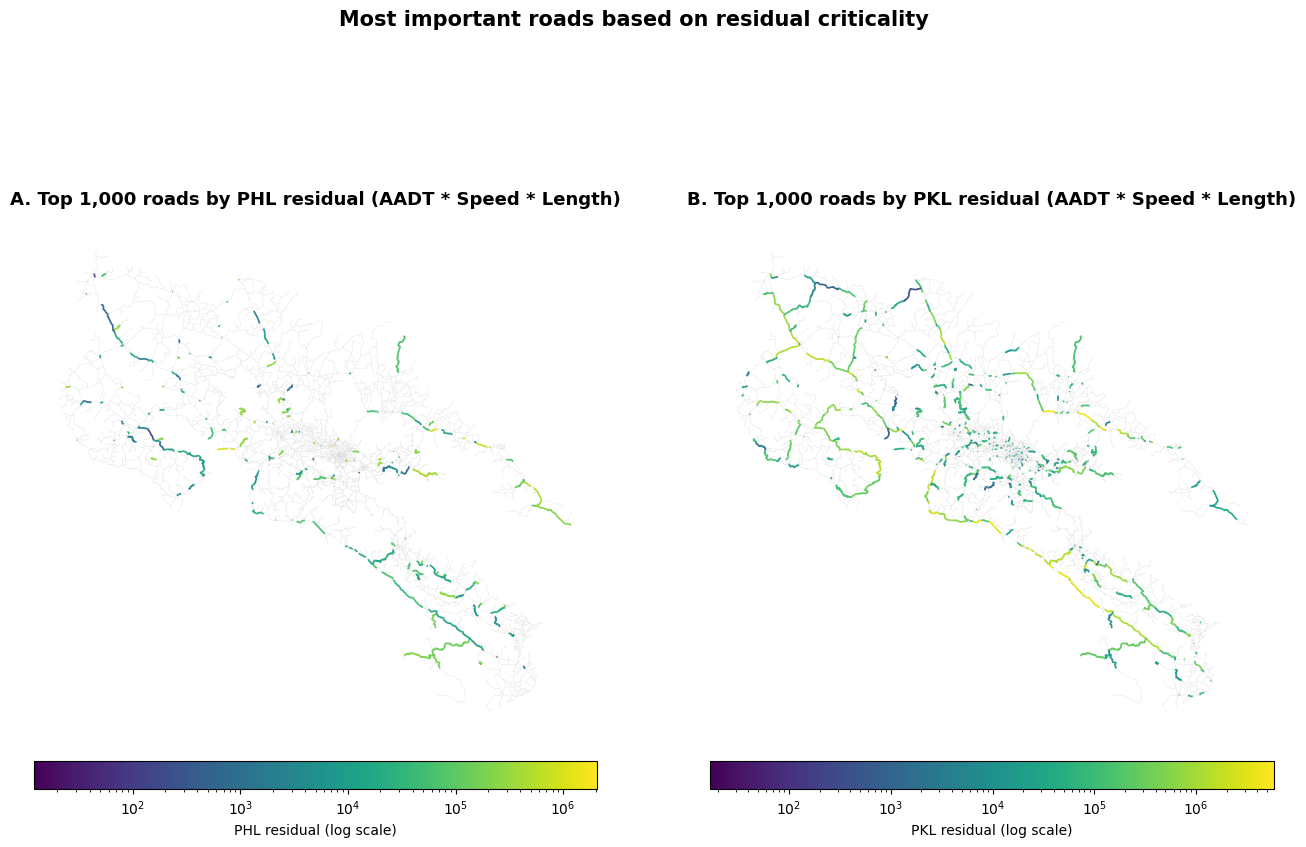

Top 1,000 PHL residual roads: max 2,073,530, sum 33,454,287
Top 1,000 PKL residual roads: max 5,768,341, sum 342,329,284


In [41]:
# residual AADT*Speed*Length
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LogNorm

top_n = 1000
cmap = "viridis"

required_residual_cols = ["phl_residual_speed_length", "pkl_residual_speed_length"]
missing_residual_cols = [
    col for col in required_residual_cols if col not in physical_results.columns
]
if missing_residual_cols:
    raise KeyError(
        "Missing residual columns: "
        + ", ".join(missing_residual_cols)
        + ". Re-run the PHL and PKL AADT * Speed * Length regression cells above before plotting."
    )

gdf_residuals_web = physical_results.to_crs(3857)

fig, axes = plt.subplots(1, 2, figsize=(16, 9), facecolor="white")


def plot_residual_panel(ax, gdf, residual_col, title):
    top_residuals = gdf.nlargest(top_n, residual_col)

    positive_values = top_residuals[residual_col].where(
        top_residuals[residual_col] > 0
    ).dropna()

    vmin = max(1.0, float(positive_values.min()))
    vmax = float(positive_values.max())
    norm = LogNorm(vmin=vmin, vmax=vmax)

    # Grey context network
    gdf.plot(
        ax=ax,
        color="#d9d9d9",
        linewidth=0.35,
        alpha=0.65,
        zorder=1,
    )

    # Top residual roads
    top_residuals.plot(
        ax=ax,
        column=residual_col,
        cmap=cmap,
        norm=norm,
        linewidth=1.25,
        alpha=0.95,
        zorder=2,
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_aspect("equal")
    ax.axis("off")

    return top_residuals, norm


top_phl, norm_phl = plot_residual_panel(
    axes[0],
    gdf_residuals_web,
    "phl_residual_speed_length",
    f"A. Top {top_n:,} roads by PHL residual (AADT * Speed * Length)",
)

top_pkl, norm_pkl = plot_residual_panel(
    axes[1],
    gdf_residuals_web,
    "pkl_residual_speed_length",
    f"B. Top {top_n:,} roads by PKL residual (AADT * Speed * Length)",
)

sm_phl = ScalarMappable(norm=norm_phl, cmap=cmap)
sm_phl.set_array([])
cbar_phl = fig.colorbar(sm_phl, ax=axes[0], orientation="horizontal", fraction=0.045, pad=0.04)
cbar_phl.set_label("PHL residual (log scale)")

sm_pkl = ScalarMappable(norm=norm_pkl, cmap=cmap)
sm_pkl.set_array([])
cbar_pkl = fig.colorbar(sm_pkl, ax=axes[1], orientation="horizontal", fraction=0.045, pad=0.04)
cbar_pkl.set_label("PKL residual (log scale)")

fig.suptitle(
    "Most important roads based on residual criticality",
    fontsize=15,
    fontweight="bold",
)

plt.savefig(
    figure_path / "top1000_phl_pkl_residual_roads.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(
    f"Top {top_n:,} PHL residual roads: "
    f"max {top_phl['phl_residual_speed_length'].max():,.0f}, "
    f"sum {top_phl['phl_residual_speed_length'].sum():,.0f}"
)
print(
    f"Top {top_n:,} PKL residual roads: "
    f"max {top_pkl['pkl_residual_speed_length'].max():,.0f}, "
    f"sum {top_pkl['pkl_residual_speed_length'].sum():,.0f}"
)

# AS: Plot both negative and positive residuals for PHL and PKL (eg bottom 1000)
# AS: quantile rank on both axis


<Axes: >

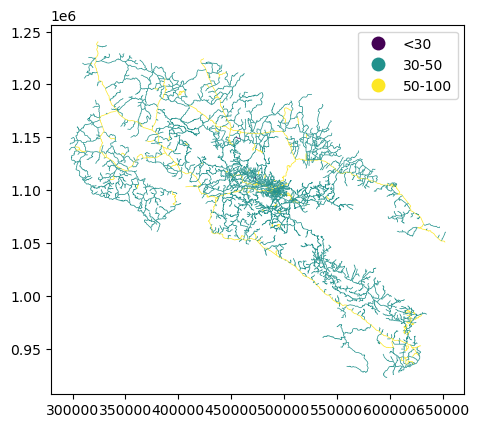

In [42]:
# Plot map of roads by speed limit
# AS: add categories for speed limit ranges
physical_results["speed_category"] = pd.cut(physical_results["speed"], bins=[0, 30, 50, 100], labels=["<30", "30-50", "50-100"])
physical_results.plot(column="speed_category", cmap="viridis", linewidth=0.5, legend=True)


## 11. Macro-economic index comparaison: Total Travel Time Cost vs Criticality (PHL and PKL)

Both share the AADT × occupancy core. The only real difference: your model computes the delay Δt_i from network topology (detour routing), 
while the macro index replaces it with the proxy speed limit × rebuild cost × rebuild time. So comparing I against PHL is a test of one specific question: 
can the expensive network model be replaced by an inventory-only formula? That's the framing to use in the paper — and your residuals are then interpretable: positive PHL residual = criticality caused by lack of redundancy, which no macro formula can see.

PHL_i  =  Δt_i · Σₖ occₖ · AADTₖ,ᵢ                  (your network model)
I_i    =  AADTᵢ · occ · SLᵢ · Creb,ᵢ · drebuild,ᵢ    (the slide's macro index)

Here is each variable, what it means, its units, which term of the Stein/HDM-4 framework it implements, and where to get a defensible Costa Rican value. Important upfront: the numbers in that snippet are illustrative placeholders I made up to show the structure — they are not calibrated values. Each one needs a sourced number before the results mean anything.

Input prices
VOT_WORK — value of working travel time, $/passenger-hour (placeholder 6.0)
What one hour of delay costs the economy when the traveller is on a work-related trip. Standard practice (HDM-4, iRAP, World Bank appraisal) is to set it equal to the average gross hourly labour cost. For Costa Rica: GDP per capita (~$13k) ÷ ~2,000 worked hours/yr ≈ $6–7/hr, which is why I picked 6.0 — but derive it properly from wage statistics (INEC) or NSDP, the way the Kerala calibration paper did it.

VOT_NONWORK — value of non-working travel time, $/passenger-hour (placeholder 2.0)
Delay on leisure/personal trips is valued lower. Convention is 25–50% of the working value (HDM-4 default practice ≈ 30%; some agencies use 0 for a conservative floor).

W_WORK — share of passenger trips that are work-related, dimensionless 0–1 (placeholder 0.30)
This is HDM-4's "Work Related Passenger Trips (%)" input. It weights the two time values into one blended rate. Ideally comes from a national travel survey; HDM-4 defaults differ by vehicle type (higher for buses than private cars), so you could make it a per-class dict like your PASSENGER_FACTORS.

CARGO_HOLDING — cost of delaying freight, $/tonne-hour (placeholder 0.9)
HDM-4's "Cargo Delay ($/hour)" input: the inventory/spoilage/interest cost of goods sitting in a stopped or detoured truck. Classical derivation: (value of average cargo per tonne × annual interest rate) / 8760, plus a perishables premium. It multiplies your thl (tonne-hours lost), so it must be per tonne-hour, not per vehicle-hour — if you take an HDM-4 per-vehicle number, divide by average payload (your FREIGHT_FACTORS).

VOC_DETOUR — vehicle operating cost of driving one extra kilometre, $/vehicle-km (all placeholders)
Fuel, tyres, maintenance parts and labour, lubricants, depreciation per km — the marginal cost of the extra distance driven on the detour. This is the number the HDM-4 RUCKS spreadsheet exists to produce: you feed it Costa Rican fuel/tyre/vehicle prices and the detour roads' roughness class, and it returns $/veh-km per vehicle type. The dict keys deliberately match your notebook's per-class AADT columns (motorcycles … heavy_trucks) so the sum works. The relative ordering (motorcycle cheapest, heavy truck most expensive) is right; the levels need a RUCKS run.

Derived quantities
vot = W_WORK·VOT_WORK + (1−W_WORK)·VOT_NONWORK — the blended value of one passenger-hour ($/pass-hr). With the placeholders: 0.3×6 + 0.7×2 = $3.20. This is the single price that converts PHL into dollars.

time_cost = vot·phl + CARGO_HOLDING·thl — Stein's C₃ term (time loss cost). Your phl already contains AADT × occupancy × delay-hours, so multiplying by a $/pass-hr price is all that's left; same for freight via thl. Units: $/day of closure (because your PHL/THL are per-day quantities).

run_cost = average_dist_disruption × Σₖ AADTₖ·VOCₖ — Stein's C₂ term (detour running cost): extra km driven per vehicle × vehicles per day per class × cost per veh-km. Units: $/day of closure. Note it uses the per-class AADT columns, not pkl — VOC is priced per vehicle-km, and pkl is passenger-km.

daily_user_loss = time_cost + run_cost — the total indirect (user) loss per day the segment is closed, $/day. This alone is already a defensible monetized criticality ranking.

Rebuild terms (the two lookups I referenced but did not define)
REBUILD_COST_PER_KM — direct reconstruction cost by road class (CLASE: Primaria/Secundaria/…), $/km. Stein's C₁ term (his unit cost × width × length; folding width into a per-class $/km is the practical simplification). Sources: CONAVI/MOPT unit construction costs, the World Bank ROCKS database of road works costs, or the per-class replacement costs in Koks et al. (2019).

REBUILD_DAYS — closure duration until the segment is rebuilt, days, by road class. Stein's d (his "duration of detour"; HYRISK makes it a function of ADT — busier roads get rebuilt faster — so a refinement is to scale it down with AADT). Sources: FEMA Hazus restoration curves per damage state, or national post-disaster reconstruction records.

consequence = C₁ (rebuild) + daily_user_loss × d — the full Stein/HYRISK failure consequence in $: direct damage plus indirect losses accumulated over the closure. (The only Stein term deliberately left out is C₄, casualties.)

One caveat to carry into the methods section: both lookup tables are per-road-class constants, so within a class the ranking of consequence is driven entirely by daily_user_loss and length — which is fine, but worth stating, and it's why the class-level rebuild assumptions mainly matter for cross-class comparisons (e.g., whether a primary corridor outranks a critical tertiary bottleneck).

## 12. Assumptions

In [ ]:

# US$/km. Anchors: Koks et al. 2019 Supp. Table 8 (LAC, ROCKS-derived);
# intermediate classes scaled with van Ginkel et al. 2021 class ratios.
REBUILD_COST_PER_KM = {
    "Primaria":       1_395_000,   # paved 2 lanes; use 4_153_850 for 4-lane sections
    "Secundaria":       465_000,   # ≈ ⅓ of primary
    "Terciaria":        140_000,   # ≈ 1/10 of primary
    "Local":             37_495,   # gravel, LAC
    "Sin clasificar":    37_495,
}
# Days of full closure until a destroyed segment is rebuilt.
# Base: Hazus 5.1 Table 7-3, roadways, extensive/complete damage = 21 days.
# Class gradient: FHWA HYRISK Table 3.2 rebuild durations scale ~1:2:3:4 as
# traffic drops (183/365/548/730 days), reflecting agency priority — applied
# here as multipliers on the Hazus base.
REBUILD_DAYS = {
    "Primaria":       21,    # ×1  — national corridor, immediate mobilization
    "Secundaria":     42,    # ×2
    "Terciaria":      63,    # ×3
    "Local":          84,    # ×4  — low-priority rural road
    "Sin clasificar": 84,
}

BRIDGE_MULTIPLIER = 4       # Hazus: bridge extensive ≈ 75 d ≈ 3.5× roadway; complete = 230 d ≈ 11×

# Unit values (economic prices; HDM-4 RUCKS gives Costa Rica-calibratable defaults)
VOT_WORK, VOT_NONWORK, W_WORK = 6.0, 2.0, 0.30   # $/pass-hr, share of work trips
CARGO_HOLDING = 0.9                              # $/tonne-hr
VOC_DETOUR = {"motorcycles": 0.08, "passenger_cars": 0.25, "pickup_trucks": 0.28,
              "buses": 0.60, "light_trucks": 0.45, "medium_trucks": 0.70,
              "heavy_trucks": 0.95}              # $/veh-km

# Baseline annual travel-time cost (HDM-4 TTC) per physical road.
# HDM-4 steps (Archondo-Callao 2010; Odoki & Kerali Vol. 4):
#   1. TripTime_v = L / OS_v          (one edge speed for all types — simplification)
#   2. PTTC_v = TripTime · Occ_v · [w·V_work + (1−w)·V_nonwork]
#   3. CTTC_v = TripTime · Y_v · V_cargo · F_cargo
#   4. TTC    = Σ_v (PTTC_v + CTTC_v + crew_v) · AADT_v · 365
# Uses the SAME unit prices as daily_user_loss so prices cancel in the
# consequence/TTC ratio. Crew time is charged to trucks only; bus drivers
# could be added symmetrically but must then also enter daily_user_loss.

F_CARGO    = 0.6      # HDM-4 cargo time factor, calibration range 0.50–0.75
CREW_TRUCK = 20.56    # $/veh-hr, HYRISK default (~2000 USD) — inflate before final runs
TRUCK_COLS = ["light_trucks", "medium_trucks", "heavy_trucks"] # TODO: pick-up should be added too!!


# # --- unit values: bring ALL sources to one base year before running ---
# VOT_WORK, VOT_NONWORK, W_WORK = 6.0, 2.0, 0.30   # placeholders → calibrate (wage data)
# CARGO_HOLDING = 0.9                              # $/tonne-hr
# CREW_TRUCK = 20.56                               # $/truck-hr, HYRISK default (~2000 USD → inflate)
# TRUCK_COLS = ["light_trucks", "medium_trucks", "heavy_trucks"]






# vot = W_WORK * VOT_WORK + (1 - W_WORK) * VOT_NONWORK

# # Stein C3 (time cost of closure, per day closed)
# time_cost = vot * gdf["phl"] + CARGO_HOLDING * gdf["thl"]

# # Stein C2 (extra running cost of the detour, per day closed)
# run_cost = gdf["average_dist_disruption"] * sum(gdf[k] * v for k, v in VOC_DETOUR.items())

# gdf["daily_user_loss"] = time_cost + run_cost                    # $/day

# def rebuild_days_hyrisk(aadt):          # FHWA/HYRISK Table 3.2 (bridge replacement)
#     if aadt < 100:   return 3 * 365
#     if aadt < 500:   return 2 * 365
#     if aadt < 1000:  return int(1.5 * 365)
#     if aadt < 5000:  return 365
#     return 183

# # Full Stein/HYRISK consequence: add rebuild terms
# gdf["consequence"] = (REBUILD_COST_PER_KM[gdf["CLASE"]] * gdf["road_length"]
#                       + gdf["daily_user_loss"] * REBUILD_DAYS[gdf["CLASE"]])

## 13. Criticality_$ or Consequence in $/day

In [44]:

df = physical_results            # one row per physical road — see issue 3


vot = W_WORK * VOT_WORK + (1 - W_WORK) * VOT_NONWORK

truck_hours = df["average_time_disruption"] * df[TRUCK_COLS].sum(axis=1)
time_cost = vot * df["phl"] + CARGO_HOLDING * df["thl"] + CREW_TRUCK * truck_hours
run_cost = df["average_dist_disruption"] * sum(df[k] * v for k, v in VOC_DETOUR.items())
df["daily_user_loss"] = time_cost + run_cost     # $/day of closure

rebuild_cost = df["CLASE"].map(REBUILD_COST_PER_KM)
rebuild_days = df["CLASE"].map(REBUILD_DAYS)     # or: df["total_aadt"].map(rebuild_days_hyrisk)
for s, name in [(rebuild_cost, "cost"), (rebuild_days, "days")]:
    missing = df.loc[s.isna(), "CLASE"].unique()
    assert len(missing) == 0, f"CLASE values without rebuild {name}: {missing}"

df["consequence"] = rebuild_cost * df["road_length"] + df["daily_user_loss"] * rebuild_days

## 14. Total Travel Time Cost (TTC) using AADTs per physical road, using the same unit values as daily_user_loss.

In [45]:

# --- Step 0: input guards ---------------------------------------------------
assert (df["speed"] > 0).all(), "zero/negative speed would give infinite trip time"
assert (df["road_length"] > 0).all(), "zero-length road"

# --- Step 1: vehicle trip time ----------------------------------------------
df["trip_time_h"] = df["road_length"] / df["speed"]   # km / (km/h) = hours

# Unit sanity: a typical segment should take minutes, not days. Catches
# road_length in metres (values ~1000× too high) or speed in m/s.
med = df["trip_time_h"].median()
assert 1e-4 < med < 1.0, f"median trip time {med:.3g} h — check length/speed units"

# --- Steps 2–3: per-vehicle costs by type ($/traversal) ----------------------
vot = W_WORK * VOT_WORK + (1 - W_WORK) * VOT_NONWORK

pttc = {v: df["trip_time_h"] * occ * vot for v, occ in PASSENGER_FACTORS.items()}
cttc = {v: df["trip_time_h"] * y * CARGO_HOLDING * F_CARGO
        for v, y in FREIGHT_FACTORS.items()}
crew = {v: df["trip_time_h"] * CREW_TRUCK for v in TRUCK_COLS}

# --- Step 4: aggregate with per-class AADT ----------------------------------
# pickup_trucks are in both passenger and freight dicts and correctly get both.
vehicle_types = set(pttc) | set(cttc) | set(crew)
daily_ttc = sum((pttc.get(v, 0) + cttc.get(v, 0) + crew.get(v, 0)) * df[v]
                for v in vehicle_types)
df["annual_ttc"] = 365 * daily_ttc                    # $/yr per segment

# --- Cross-check: expanded per-type form == collapsed algebraic form ---------
passengers = sum(df[c] * f for c, f in PASSENGER_FACTORS.items())
tonnes     = sum(df[c] * f for c, f in FREIGHT_FACTORS.items())
trucks     = df[TRUCK_COLS].sum(axis=1)
compact = 365 * df["trip_time_h"] * (vot * passengers
                                     + CARGO_HOLDING * F_CARGO * tonnes
                                     + CREW_TRUCK * trucks)
assert np.allclose(df["annual_ttc"], compact), "expanded vs compact TTC mismatch"

assert np.isfinite(df["annual_ttc"]).all(), "non-finite annual TTC"
assert (df.loc[df["total_aadt"] > 0, "annual_ttc"] > 0).all(), \
    "trafficked road with zero baseline TTC"

# --- Comparison metric (only if consequence has been computed upstream) ------
if "consequence" in df.columns:
    df["consequence_ratio"] = (df["consequence"]
                               / df["annual_ttc"].where(df["annual_ttc"] > 0))

print(df[["trip_time_h", "annual_ttc"]].describe().round(4).to_string())
print(f"\nNetwork total baseline TTC: ${df['annual_ttc'].sum():,.0f}/yr")
if "consequence_ratio" in df.columns:
    print("\nConsequence / annual TTC (dimensionless, years of own service value):")
    print(df["consequence_ratio"].describe().round(2).to_string())

       trip_time_h    annual_ttc
count    5012.0000  5.012000e+03
mean        0.0705  1.521866e+06
std         0.0922  2.389170e+06
min         0.0000  2.700000e-03
25%         0.0133  2.545748e+05
50%         0.0388  7.390018e+05
75%         0.0925  1.834444e+06
max         1.5154  6.226677e+07

Network total baseline TTC: $7,627,591,888/yr

Consequence / annual TTC (dimensionless, years of own service value):
count    5.012000e+03
mean     4.560739e+04
std      3.109787e+06
min      1.000000e-02
25%      1.400000e-01
50%      6.200000e-01
75%      1.780000e+00
max      2.200436e+08


Text(0, 0.5, 'Consequence (USD)')

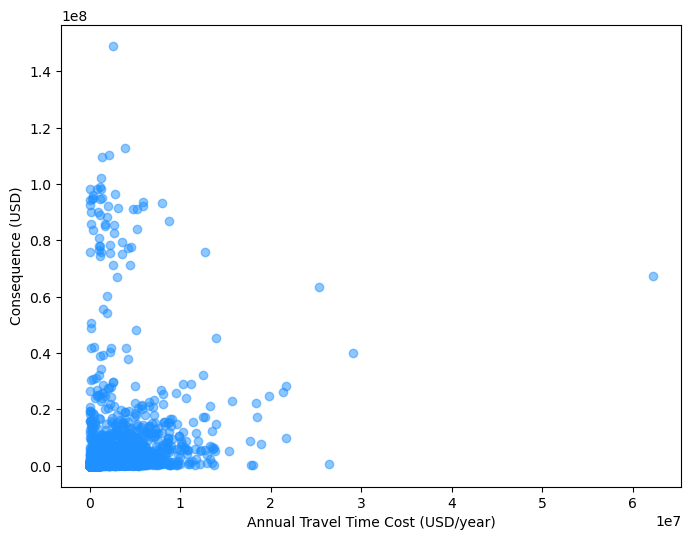

In [46]:
#plot consequence vs annual_ttc
plt.figure(figsize=(8, 6))
plt.scatter(df["annual_ttc"], df["consequence"], alpha=0.5,
            color="#1E90FF", label="AADT observed")
# plt.xscale("log")
# plt.yscale("log")
plt.xlabel("Annual Travel Time Cost (USD/year)")
plt.ylabel("Consequence (USD)")

Text(0, 0.5, 'Consequence (USD)')

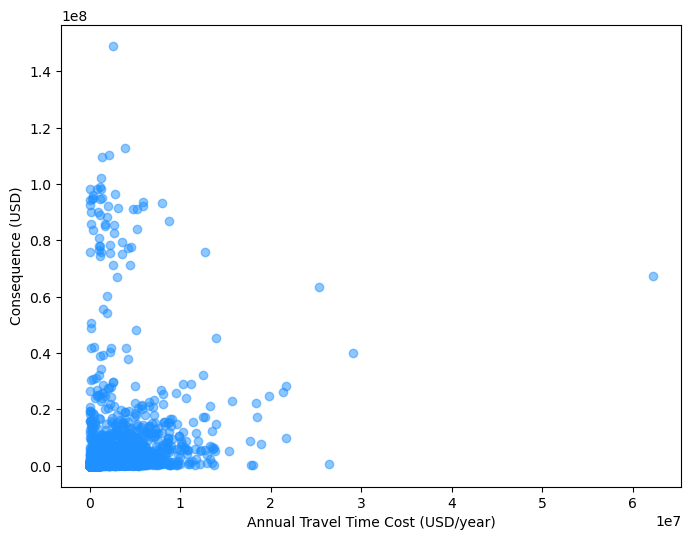

In [47]:
df_valid = df[["annual_ttc", "consequence"]].dropna()
plt.figure(figsize=(8, 6))
plt.scatter(df_valid["annual_ttc"], df_valid["consequence"], alpha=0.5,
            color="#1E90FF", label="AADT observed")
# plt.xscale("log")
# plt.yscale("log")
plt.xlabel("Annual Travel Time Cost (USD/year)")
plt.ylabel("Consequence (USD)")

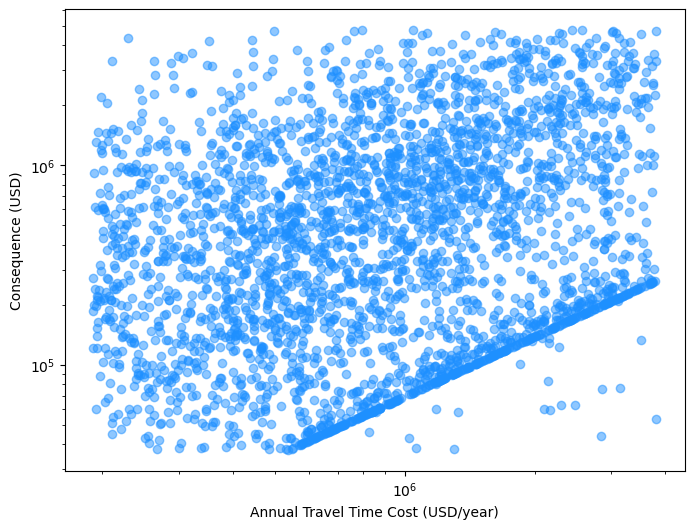

In [48]:
# select 5th to 95th percentile for better visualization
ttc_95th = df_valid["annual_ttc"].quantile(0.90)
consequence_95th = df_valid["consequence"].quantile(0.90)
ttc_5th = df_valid["annual_ttc"].quantile(0.20)
consequence_5th = df_valid["consequence"].quantile(0.10)

df_valid = df_valid.loc[(df_valid["annual_ttc"] >= ttc_5th) & (df_valid["annual_ttc"] <= ttc_95th) &
                        (df_valid["consequence"] >= consequence_5th) & (df_valid["consequence"] <= consequence_95th)]

plt.figure(figsize=(8, 6))
plt.scatter(df_valid["annual_ttc"], df_valid["consequence"], alpha=0.5,
            color="#1E90FF", label="AADT observed")
plt.xlabel("Annual Travel Time Cost (USD/year)")
plt.ylabel("Consequence (USD)")
plt.xscale("log")
plt.yscale("log")

In [49]:
# Roads that are more critical than their traffic volume alone would suggest.
slope, intercept, r, p, se = stats.linregress(df_valid['annual_ttc'], df_valid["consequence"])
print(f"Annual TTC ~ Consequence : r² = {r ** 2:.3f}, slope = {slope:.2f}, p = {p:.3g}")

df_valid["consequence_expected"] = intercept + slope * df_valid["annual_ttc"]
df_valid["consequence_residual"] = df_valid["consequence"] - df_valid["consequence_expected"]

Annual TTC ~ Consequence : r² = 0.062, slope = 0.27, p = 8.18e-45


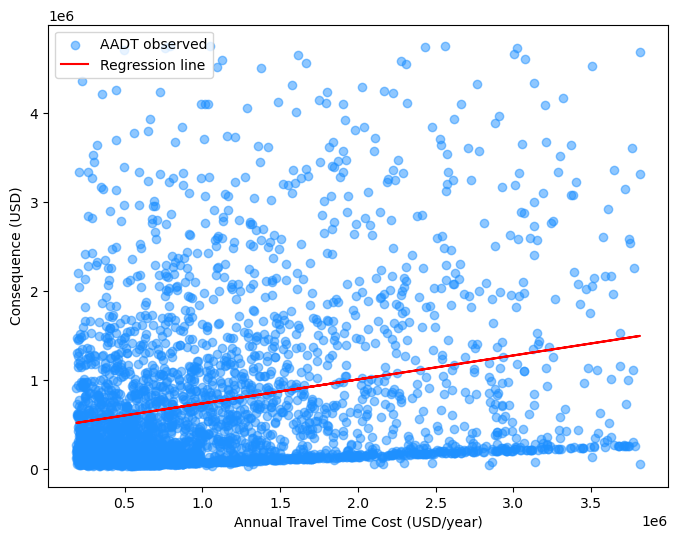

In [50]:
# PLot with regression line
plt.figure(figsize=(8, 6))
plt.scatter(df_valid["annual_ttc"], df_valid["consequence"], alpha=0.5,
            color="#1E90FF", label="AADT observed")
plt.plot(df_valid["annual_ttc"], df_valid["consequence_expected"], color="red", label="Regression line")
plt.xlabel("Annual Travel Time Cost (USD/year)")
plt.ylabel("Consequence (USD)")
plt.legend()
plt.show()

In [51]:
# Log tranformation value
# Log transformation for better visualization

Text(0, 0.5, 'PHL (Hours)')

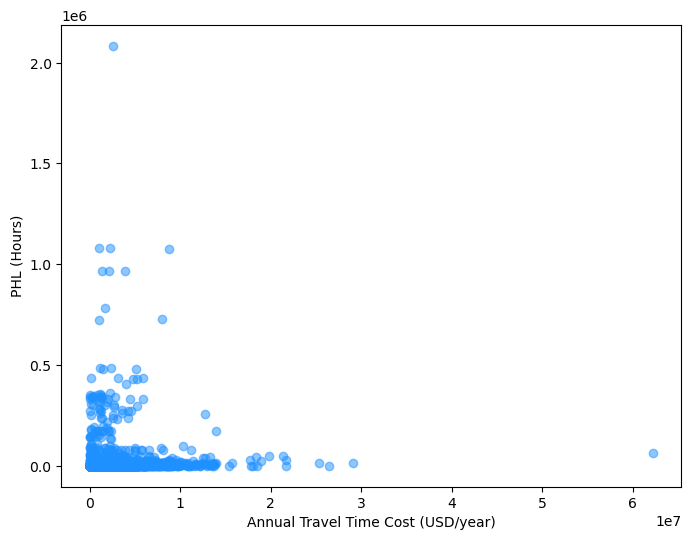

In [52]:
plt.figure(figsize=(8, 6))
plt.scatter(df["annual_ttc"], df["phl"], alpha=0.5,
            color="#1E90FF", label="AADT observed")
# plt.xscale("log")
# plt.yscale("log")
plt.xlabel("Annual Travel Time Cost (USD/year)")
plt.ylabel("PHL (Hours)")

## 14. Log PHL vs Annual Travel Time Cost

Text(0, 0.5, 'Log1p PHL (Hours)')

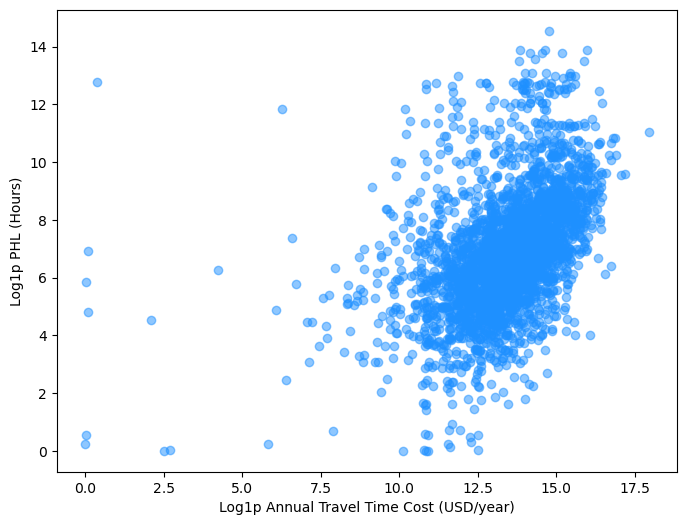

In [53]:
# Log transformation PHL and annual_ttc
df_valid = df[["annual_ttc", "phl"]].dropna().copy()
df_valid = df_valid.loc[
    np.isfinite(df_valid["annual_ttc"])
    & np.isfinite(df_valid["phl"])
    & (df_valid["annual_ttc"] > 0)
    & (df_valid["phl"] > 0)
].copy()
df_valid["log_annual_ttc"] = np.log1p(df_valid["annual_ttc"])
df_valid["log_phl"] = np.log1p(df_valid["phl"])
#plot log-log regression
plt.figure(figsize=(8, 6))
plt.scatter(df_valid["log_annual_ttc"], df_valid["log_phl"], alpha=0.5,
            color="#1E90FF", label="AADT observed")
plt.xlabel("Log1p Annual Travel Time Cost (USD/year)")
plt.ylabel("Log1p PHL (Hours)")

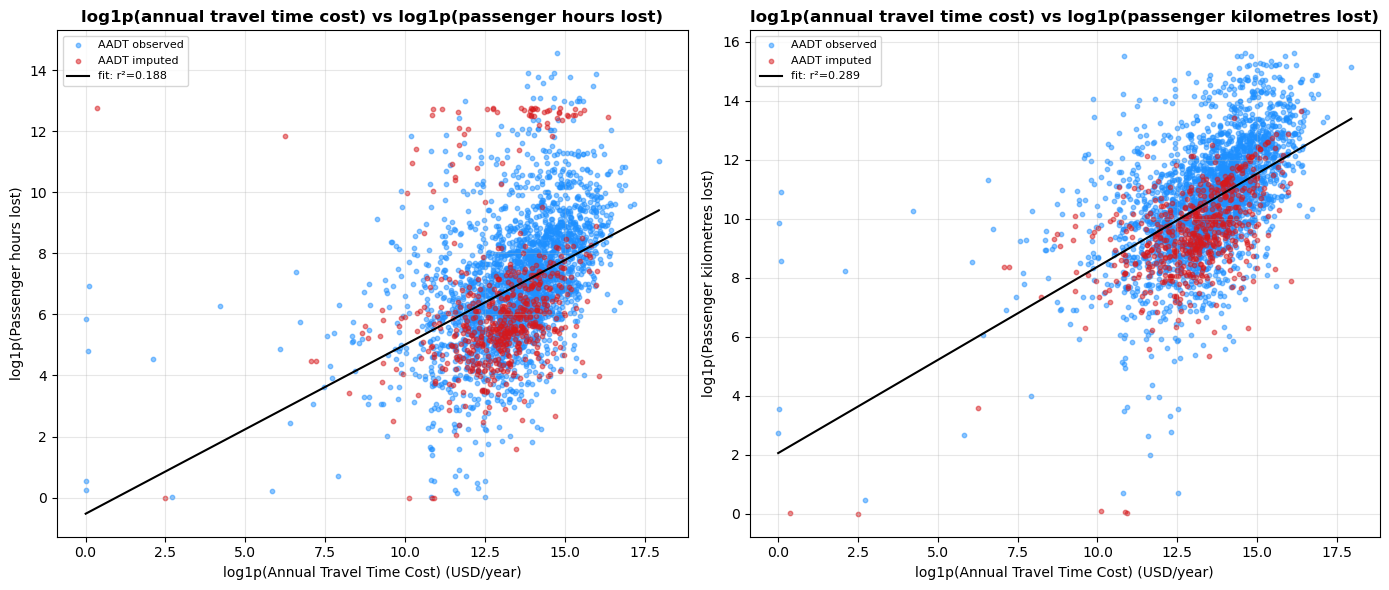

In [54]:
# Log-transformed Annual Travel Time Cost vs criticality

if "annual_ttc" not in physical_results.columns:
    raise KeyError(
        "Missing annual_ttc. Re-run the Annual Travel Time Cost cell above before plotting."
    )

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), facecolor="white")

for ax, metric, label in [
    (ax1, "phl", "Passenger hours lost"),
    (ax2, "pkl", "Passenger kilometres lost"),
]:
    df_valid = physical_results[
        ["annual_ttc", metric, "aadt_imputed"]
    ].dropna().copy()
    df_valid = df_valid.loc[
        np.isfinite(df_valid["annual_ttc"])
        & np.isfinite(df_valid[metric])
        & (df_valid["annual_ttc"] > 0)
        & (df_valid[metric] > 0)
    ].copy()
    df_valid["log_annual_ttc"] = np.log1p(df_valid["annual_ttc"])
    df_valid[f"log_{metric}"] = np.log1p(df_valid[metric])

    observed = df_valid.loc[~df_valid["aadt_imputed"].astype(bool)]
    imputed = df_valid.loc[df_valid["aadt_imputed"].astype(bool)]

    ax.scatter(
        observed["log_annual_ttc"],
        observed[f"log_{metric}"],
        s=10,
        alpha=0.5,
        color="#1E90FF",
        label="AADT observed",
    )
    ax.scatter(
        imputed["log_annual_ttc"],
        imputed[f"log_{metric}"],
        s=10,
        alpha=0.5,
        color="#d7191c",
        label="AADT imputed",
    )

    if len(df_valid) >= 2 and df_valid["log_annual_ttc"].nunique() > 1:
        slope, intercept, r, p, se = stats.linregress(
            df_valid["log_annual_ttc"], df_valid[f"log_{metric}"]
        )
        xs = np.linspace(
            df_valid["log_annual_ttc"].min(),
            df_valid["log_annual_ttc"].max(),
            100,
        )
        ax.plot(
            xs,
            intercept + slope * xs,
            color="black",
            lw=1.5,
            label=f"fit: r²={r ** 2:.3f}",
        )

    ax.set_xlabel("log1p(Annual Travel Time Cost) (USD/year)")
    ax.set_ylabel(f"log1p({label})")
    ax.set_title(
        f"log1p(annual travel time cost) vs log1p({label.lower()})",
        fontsize=12,
        fontweight="bold",
    )
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    figure_path / "SPOF_log_annual_ttc_vs_criticality.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


log1p(PHL) ~ log1p(Annual TTC) : r² = 0.188, slope = 0.55, p = 7.48e-139
log1p(PKL) ~ log1p(Annual TTC) : r² = 0.289, slope = 0.63, p = 1.73e-226


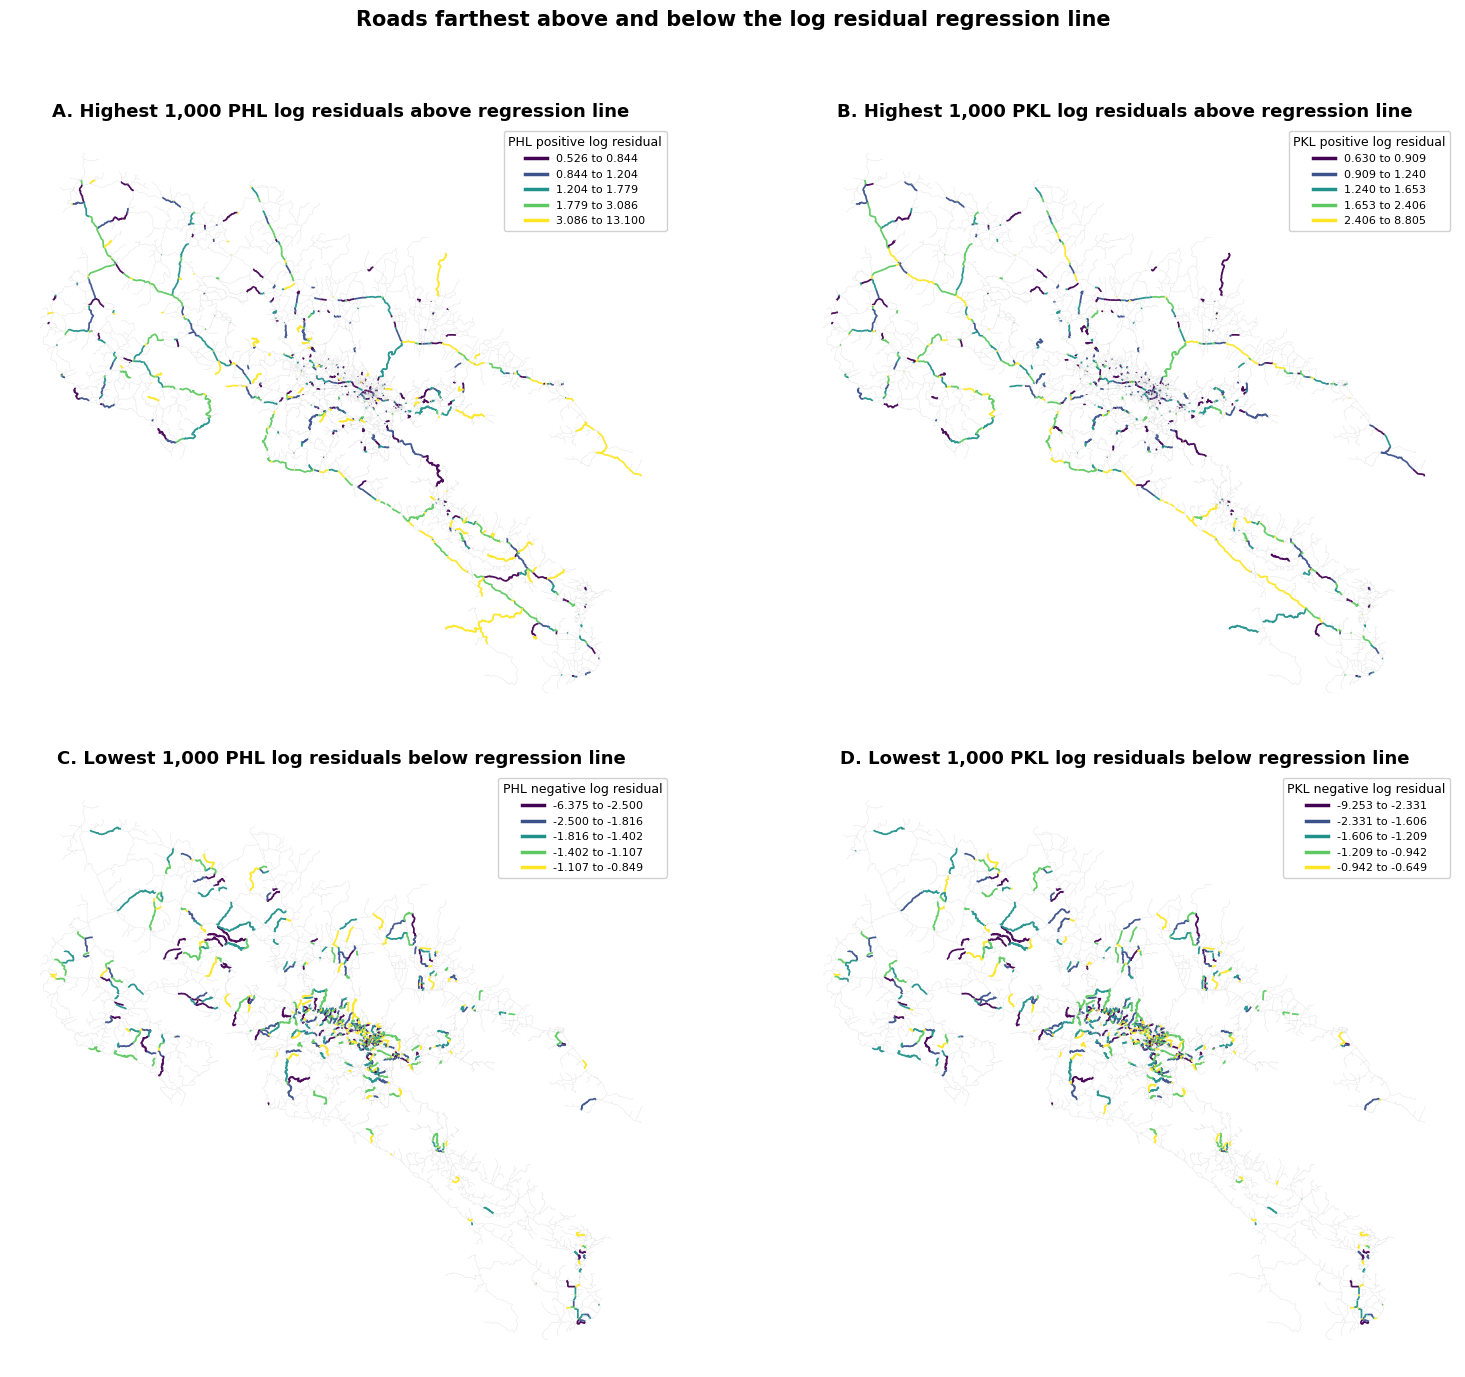

Highest 1,000 PHL log residual roads: max 13.100, sum 2,035.199
Highest 1,000 PKL log residual roads: max 8.805, sum 1,715.817
Lowest 1,000 PHL log residual roads: min -6.374, sum -1,872.071
Lowest 1,000 PKL log residual roads: min -9.252, sum -1,717.334


In [ ]:
# Plot Log residuals from Annual Travel Time Cost

from matplotlib.lines import Line2D

bins_n = 5
top_n = 1000
cmap = "viridis"

if "annual_ttc" not in physical_results.columns:
    raise KeyError(
        "Missing annual_ttc. Run the Annual Travel Time Cost cell before plotting."
    )

physical_results["log_annual_ttc"] = np.nan
annual_ttc_mask = (
    np.isfinite(physical_results["annual_ttc"])
    & (physical_results["annual_ttc"] > 0)
)
physical_results.loc[annual_ttc_mask, "log_annual_ttc"] = np.log1p(
    physical_results.loc[annual_ttc_mask, "annual_ttc"]
)

residual_specs = [
    ("phl", "PHL"),
    ("pkl", "PKL"),
]

for metric, metric_label in residual_specs:
    log_metric_col = f"log_{metric}"
    expected_col = f"log_{metric}_expected_annual_ttc"
    residual_col = f"log_{metric}_residual_annual_ttc"

    df_valid = physical_results[["annual_ttc", metric]].dropna().copy()
    df_valid = df_valid.loc[
        np.isfinite(df_valid["annual_ttc"])
        & np.isfinite(df_valid[metric])
        & (df_valid["annual_ttc"] > 0)
        & (df_valid[metric] > 0)
    ].copy()
    df_valid["log_annual_ttc"] = np.log1p(df_valid["annual_ttc"])
    df_valid[log_metric_col] = np.log1p(df_valid[metric])

    if len(df_valid) < 2 or df_valid["log_annual_ttc"].nunique() <= 1:
        raise ValueError(
            f"Not enough valid rows to fit log1p({metric_label}) ~ log1p(Annual TTC)."
        )

    slope, intercept, r, p, se = stats.linregress(
        df_valid["log_annual_ttc"], df_valid[log_metric_col]
    )
    print(
        f"log1p({metric_label}) ~ log1p(Annual TTC) : "
        f"r² = {r ** 2:.3f}, slope = {slope:.2f}, p = {p:.3g}"
    )

    physical_results[log_metric_col] = np.nan
    physical_results[expected_col] = np.nan
    physical_results[residual_col] = np.nan
    physical_results.loc[df_valid.index, log_metric_col] = df_valid[log_metric_col]
    physical_results.loc[df_valid.index, expected_col] = (
        intercept + slope * df_valid["log_annual_ttc"]
    )
    physical_results.loc[df_valid.index, residual_col] = (
        physical_results.loc[df_valid.index, log_metric_col]
        - physical_results.loc[df_valid.index, expected_col]
    )

gdf_log_residuals_web = physical_results.to_crs(3857)

fig, axes = plt.subplots(2, 2, figsize=(16, 14), facecolor="white")


def format_interval(interval):
    return f"{interval.left:,.3f} to {interval.right:,.3f}"


def plot_log_residual_tail(ax, gdf, residual_col, title, tail, legend_title):
    valid_residuals = gdf.loc[gdf[residual_col].notna()].copy()
    if tail == "highest":
        selected = valid_residuals.loc[valid_residuals[residual_col] > 0].nlargest(
            top_n, residual_col
        )
    elif tail == "lowest":
        selected = valid_residuals.loc[valid_residuals[residual_col] < 0].nsmallest(
            top_n, residual_col
        )
    else:
        raise ValueError(f"Unknown residual tail: {tail}")

    if selected.empty:
        raise ValueError(f"No {tail} residual values found in {residual_col}.")

    selected = selected.copy()
    bin_count = min(bins_n, selected[residual_col].nunique())
    if bin_count < 1:
        raise ValueError(f"No distinct values found in {residual_col}.")

    bin_col = f"{residual_col}_{tail}_bin"
    selected[bin_col] = pd.qcut(
        selected[residual_col],
        q=bin_count,
        duplicates="drop",
    )
    categories = selected[bin_col].cat.categories
    colors = plt.get_cmap(cmap, len(categories))

    # Grey context network
    gdf.plot(
        ax=ax,
        color="#d9d9d9",
        linewidth=0.35,
        alpha=0.65,
        zorder=1,
    )

    # Top residual roads in the selected tail, grouped into five legend bins
    handles = []
    for i, category in enumerate(categories):
        subset = selected.loc[selected[bin_col] == category]
        if subset.empty:
            continue
        color = colors(i)
        subset.plot(
            ax=ax,
            color=color,
            linewidth=1.25,
            alpha=0.95,
            zorder=2 + i,
        )
        handles.append(
            Line2D([0], [0], color=color, lw=2.5, label=format_interval(category))
        )

    ax.legend(
        handles=handles,
        title=legend_title,
        loc="upper right",
        fontsize=8,
        title_fontsize=9,
        frameon=True,
        framealpha=0.9,
        facecolor="white",
        edgecolor="#cccccc",
    )
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_aspect("equal")
    ax.axis("off")

    return selected


high_log_phl = plot_log_residual_tail(
    axes[0, 0],
    gdf_log_residuals_web,
    "log_phl_residual_annual_ttc",
    f"A. Highest {top_n:,} PHL log residuals above regression line",
    tail="highest",
    legend_title="PHL positive log residual",
)

high_log_pkl = plot_log_residual_tail(
    axes[0, 1],
    gdf_log_residuals_web,
    "log_pkl_residual_annual_ttc",
    f"B. Highest {top_n:,} PKL log residuals above regression line",
    tail="highest",
    legend_title="PKL positive log residual",
)

low_log_phl = plot_log_residual_tail(
    axes[1, 0],
    gdf_log_residuals_web,
    "log_phl_residual_annual_ttc",
    f"C. Lowest {top_n:,} PHL log residuals below regression line",
    tail="lowest",
    legend_title="PHL negative log residual",
)

low_log_pkl = plot_log_residual_tail(
    axes[1, 1],
    gdf_log_residuals_web,
    "log_pkl_residual_annual_ttc",
    f"D. Lowest {top_n:,} PKL log residuals below regression line",
    tail="lowest",
    legend_title="PKL negative log residual",
)

fig.suptitle(
    "Roads farthest above and below the log residual regression line",
    fontsize=15,
    fontweight="bold",
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(
    figure_path / "top_bottom1000_log_phl_pkl_residual_roads.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(
    f"Highest {top_n:,} PHL log residual roads: "
    f"max {high_log_phl['log_phl_residual_annual_ttc'].max():,.3f}, "
    f"sum {high_log_phl['log_phl_residual_annual_ttc'].sum():,.3f}"
)
print(
    f"Highest {top_n:,} PKL log residual roads: "
    f"max {high_log_pkl['log_pkl_residual_annual_ttc'].max():,.3f}, "
    f"sum {high_log_pkl['log_pkl_residual_annual_ttc'].sum():,.3f}"
)
print(
    f"Lowest {top_n:,} PHL log residual roads: "
    f"min {low_log_phl['log_phl_residual_annual_ttc'].min():,.3f}, "
    f"sum {low_log_phl['log_phl_residual_annual_ttc'].sum():,.3f}"
)
print(
    f"Lowest {top_n:,} PKL log residual roads: "
    f"min {low_log_pkl['log_pkl_residual_annual_ttc'].min():,.3f}, "
    f"sum {low_log_pkl['log_pkl_residual_annual_ttc'].sum():,.3f}"
)

## 15. Log Consequence vs Log Annual Travel Time Cost

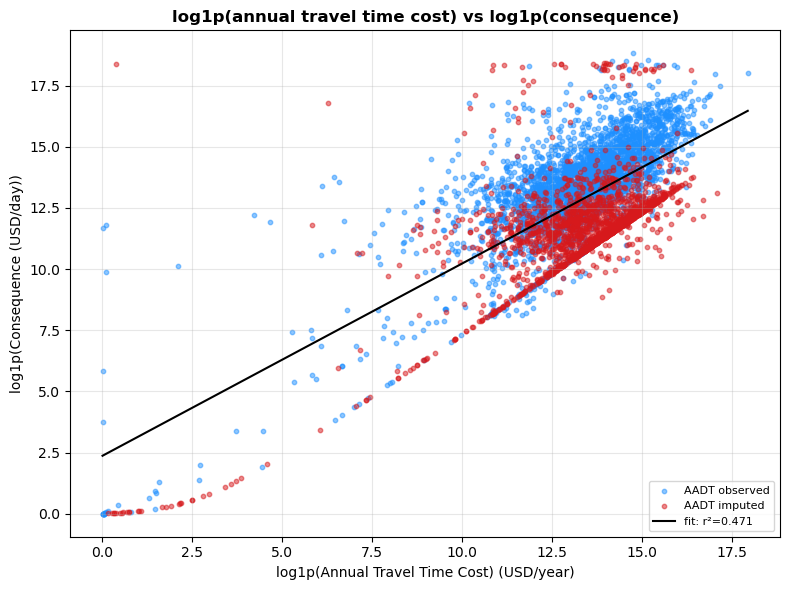

In [56]:
# Log-transformed Annual Travel Time Cost vs consequence
required_cols = ["annual_ttc", "consequence", "aadt_imputed"]
missing_cols = [col for col in required_cols if col not in physical_results.columns]
if missing_cols:
    raise KeyError(
        "Missing columns: "
        + ", ".join(missing_cols)
        + ". Run the Annual Travel Time Cost and consequence cells before plotting."
    )

metric = "consequence"
label = "Consequence (USD/day)"

fig, ax = plt.subplots(1, 1, figsize=(8, 6), facecolor="white")

df_valid = physical_results[["annual_ttc", metric, "aadt_imputed"]].dropna().copy()
df_valid = df_valid.loc[
    np.isfinite(df_valid["annual_ttc"])
    & np.isfinite(df_valid[metric])
    & (df_valid["annual_ttc"] > 0)
    & (df_valid[metric] > 0)
].copy()

if df_valid.empty:
    raise ValueError("No positive finite annual_ttc and consequence values available to plot.")

df_valid["log_annual_ttc"] = np.log1p(df_valid["annual_ttc"])
df_valid[f"log_{metric}"] = np.log1p(df_valid[metric])

observed = df_valid.loc[~df_valid["aadt_imputed"].astype(bool)]
imputed = df_valid.loc[df_valid["aadt_imputed"].astype(bool)]

ax.scatter(
    observed["log_annual_ttc"],
    observed[f"log_{metric}"],
    s=10,
    alpha=0.5,
    color="#1E90FF",
    label="AADT observed",
)
ax.scatter(
    imputed["log_annual_ttc"],
    imputed[f"log_{metric}"],
    s=10,
    alpha=0.5,
    color="#d7191c",
    label="AADT imputed",
)

if len(df_valid) >= 2 and df_valid["log_annual_ttc"].nunique() > 1:
    slope, intercept, r, p, se = stats.linregress(
        df_valid["log_annual_ttc"], df_valid[f"log_{metric}"]
    )
    xs = np.linspace(
        df_valid["log_annual_ttc"].min(),
        df_valid["log_annual_ttc"].max(),
        100,
    )
    ax.plot(
        xs,
        intercept + slope * xs,
        color="black",
        lw=1.5,
        label=f"fit: r²={r ** 2:.3f}",
    )

ax.set_xlabel("log1p(Annual Travel Time Cost) (USD/year)")
ax.set_ylabel(f"log1p({label})")
ax.set_title(
    "log1p(annual travel time cost) vs log1p(consequence)",
    fontsize=12,
    fontweight="bold",
)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    figure_path / "SPOF_log_annual_ttc_vs_consequence.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

log1p(Consequence) ~ log1p(Annual TTC) : r² = 0.471, slope = 0.79, p = 0


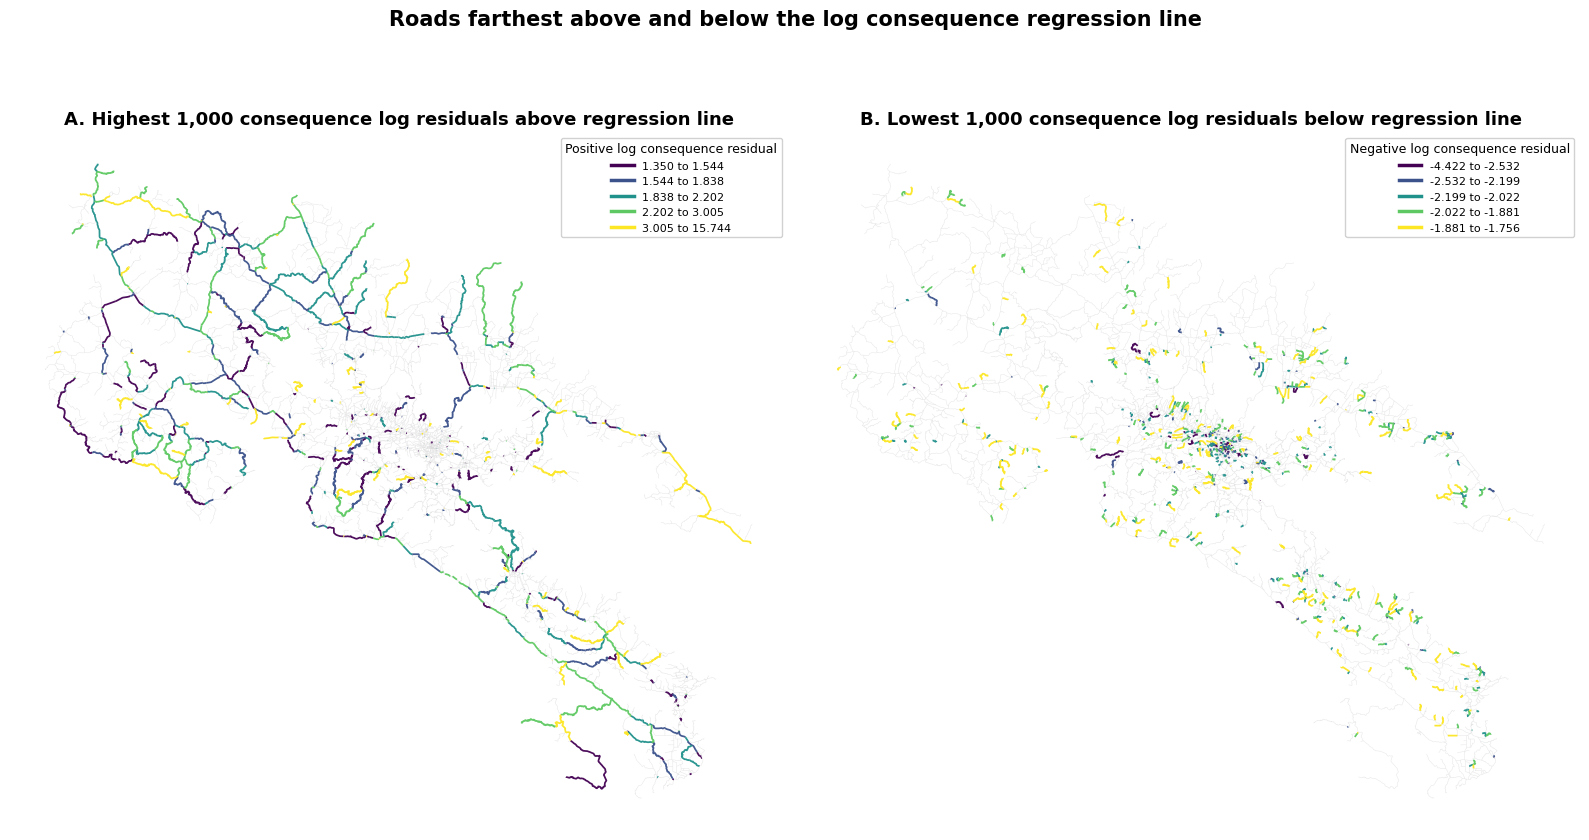

Highest 1,000 consequence log residual roads: max 15.744, sum 2,402.000
Lowest 1,000 consequence log residual roads: min -4.421, sum -2,244.494


In [ ]:
# Plot Log consequence residuals from Annual Travel Time Cost
from matplotlib.lines import Line2D

bins_n = 5
top_n = 1000
cmap = "viridis"

required_cols = ["annual_ttc", "consequence"]
missing_cols = [col for col in required_cols if col not in physical_results.columns]
if missing_cols:
    raise KeyError(
        "Missing columns: "
        + ", ".join(missing_cols)
        + ". Run the Annual Travel Time Cost and consequence cells before plotting."
    )

metric = "consequence"
metric_label = "Consequence"
log_metric_col = "log_consequence"
expected_col = "log_consequence_expected_annual_ttc"
residual_col = "log_consequence_residual_annual_ttc"

physical_results["log_annual_ttc"] = np.nan
physical_results[log_metric_col] = np.nan
physical_results[expected_col] = np.nan
physical_results[residual_col] = np.nan

annual_ttc_mask = (
    np.isfinite(physical_results["annual_ttc"])
    & (physical_results["annual_ttc"] > 0)
)
physical_results.loc[annual_ttc_mask, "log_annual_ttc"] = np.log1p(
    physical_results.loc[annual_ttc_mask, "annual_ttc"]
)

df_valid = physical_results[["annual_ttc", metric]].dropna().copy()
df_valid = df_valid.loc[
    np.isfinite(df_valid["annual_ttc"])
    & np.isfinite(df_valid[metric])
    & (df_valid["annual_ttc"] > 0)
    & (df_valid[metric] > 0)
].copy()

if len(df_valid) < 2:
    raise ValueError(
        "Not enough positive finite rows to fit log1p(Consequence) ~ log1p(Annual TTC)."
    )

df_valid["log_annual_ttc"] = np.log1p(df_valid["annual_ttc"])
df_valid[log_metric_col] = np.log1p(df_valid[metric])

if df_valid["log_annual_ttc"].nunique() <= 1:
    raise ValueError(
        "Not enough distinct log1p(Annual TTC) values to fit the consequence regression."
    )

slope, intercept, r, p, se = stats.linregress(
    df_valid["log_annual_ttc"], df_valid[log_metric_col]
)
print(
    f"log1p({metric_label}) ~ log1p(Annual TTC) : "
    f"r² = {r ** 2:.3f}, slope = {slope:.2f}, p = {p:.3g}"
)

physical_results.loc[df_valid.index, log_metric_col] = df_valid[log_metric_col]
physical_results.loc[df_valid.index, expected_col] = (
    intercept + slope * df_valid["log_annual_ttc"]
)
physical_results.loc[df_valid.index, residual_col] = (
    physical_results.loc[df_valid.index, log_metric_col]
    - physical_results.loc[df_valid.index, expected_col]
)

gdf_log_consequence_residuals_web = physical_results.to_crs(3857)

fig, axes = plt.subplots(1, 2, figsize=(16, 9), facecolor="white")


def format_interval(interval):
    return f"{interval.left:,.3f} to {interval.right:,.3f}"


def plot_log_residual_tail(ax, gdf, residual_col, title, tail, legend_title):
    valid_residuals = gdf.loc[gdf[residual_col].notna()].copy()
    if tail == "highest":
        selected = valid_residuals.loc[valid_residuals[residual_col] > 0].nlargest(
            top_n, residual_col
        )
    elif tail == "lowest":
        selected = valid_residuals.loc[valid_residuals[residual_col] < 0].nsmallest(
            top_n, residual_col
        )
    else:
        raise ValueError(f"Unknown residual tail: {tail}")

    if selected.empty:
        raise ValueError(f"No {tail} residual values found in {residual_col}.")

    selected = selected.copy()
    bin_count = min(bins_n, selected[residual_col].nunique())
    if bin_count < 1:
        raise ValueError(f"No distinct values found in {residual_col}.")

    bin_col = f"{residual_col}_{tail}_bin"
    selected[bin_col] = pd.qcut(
        selected[residual_col],
        q=bin_count,
        duplicates="drop",
    )
    categories = selected[bin_col].cat.categories
    colors = plt.get_cmap(cmap, len(categories))

    # Grey context network
    gdf.plot(
        ax=ax,
        color="#d9d9d9",
        linewidth=0.35,
        alpha=0.65,
        zorder=1,
    )

    # Consequence residual roads in the selected tail, grouped into five legend bins
    handles = []
    for i, category in enumerate(categories):
        subset = selected.loc[selected[bin_col] == category]
        if subset.empty:
            continue
        color = colors(i)
        subset.plot(
            ax=ax,
            color=color,
            linewidth=1.25,
            alpha=0.95,
            zorder=2 + i,
        )
        handles.append(
            Line2D([0], [0], color=color, lw=2.5, label=format_interval(category))
        )

    ax.legend(
        handles=handles,
        title=legend_title,
        loc="upper right",
        fontsize=8,
        title_fontsize=9,
        frameon=True,
        framealpha=0.9,
        facecolor="white",
        edgecolor="#cccccc",
    )
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_aspect("equal")
    ax.axis("off")

    return selected


high_log_consequence = plot_log_residual_tail(
    axes[0],
    gdf_log_consequence_residuals_web,
    residual_col,
    f"A. Highest {top_n:,} consequence log residuals above regression line",
    tail="highest",
    legend_title="Positive log consequence residual",
)

low_log_consequence = plot_log_residual_tail(
    axes[1],
    gdf_log_consequence_residuals_web,
    residual_col,
    f"B. Lowest {top_n:,} consequence log residuals below regression line",
    tail="lowest",
    legend_title="Negative log consequence residual",
)

fig.suptitle(
    "Roads farthest above and below the log consequence regression line",
    fontsize=15,
    fontweight="bold",
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(
    figure_path / "top_bottom1000_log_consequence_residual_roads.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(
    f"Highest {top_n:,} consequence log residual roads: "
    f"max {high_log_consequence[residual_col].max():,.3f}, "
    f"sum {high_log_consequence[residual_col].sum():,.3f}"
)
print(
    f"Lowest {top_n:,} consequence log residual roads: "
    f"min {low_log_consequence[residual_col].min():,.3f}, "
    f"sum {low_log_consequence[residual_col].sum():,.3f}"
)